# Penanda Linguistik ETHICS Gender — v1.5 candidate

Notebook ini mengukur perbedaan respons pada soal yang sama untuk enam model,
sembilan skenario dan empat subset. Analisis memakai artefak marker v1.6 yang
dibekukan: 21 ukuran umum (3 ukuran teks + 18 marker), 11 marker gender,
komposisi pembuka, serta kamus kata gender sebagai pemeriksaan tambahan.

**Status: candidate.** Audit precision/recall dua penilai, agreement, dan
adjudikasi masih diperlukan. Angka dan bintang pada grafik merupakan hasil
statistik kandidat. Seluruh respons dengan teks penjelasan tersedia, termasuk
abstain, masuk analisis utama; missing/technical-only mempunyai nilai marker NA.


In [1]:
from pathlib import Path
import hashlib
import json
import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
             if (p / "src").is_dir() and (p / "result").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Buka notebook dari dalam repositori TugasAkhir")
BUNDLE = ROOT / 'result/ETHICS/reports/Gender_Persona/linguistic_markers/analysis/gender_ethics_lm_workspace_v1_5_20260909_r2'
manifest = json.loads((BUNDLE / "manifest.json").read_text(encoding="utf-8"))
verification = json.loads((BUNDLE / "workspace_validation.json").read_text(encoding="utf-8"))
assert verification["valid"], verification["failures"]
assert manifest["hidden_reasoning_used"] is False
assert manifest["result_status"] == "candidate"
artifacts = json.loads((BUNDLE / "workspace_artifact_hashes.json").read_text(encoding="utf-8"))
for relative_path, expected in artifacts.items():
    with (BUNDLE / relative_path).open("rb") as handle:
        assert hashlib.file_digest(handle, "sha256").hexdigest() == expected, relative_path

def table(name):
    return pd.read_csv(BUNDLE / name)

def figures(group):
    for path in group:
        display(Image(filename=str(BUNDLE / path), width=1500))

def results(name):
    data = table(name)
    columns = [c for c in ["model_id", "subset", "identity", "condition", "outcome_id", "contrast_id",
        "n_pairs", "n_nonzero", "test_used", "median_paired_delta", "rank_biserial", "prevalence_left", "prevalence_right",
        "prevalence_delta", "ci_low", "ci_high", "p_raw", "p_holm", "raw_count_sum_left", "raw_count_sum_right"] if c in data]
    display(data[columns].head(24))
    display(Markdown(f"Tabel lengkap: `{name}` ({len(data):,} baris)"))

pd.set_option("display.max_columns", 24)
print("Bundle:", BUNDLE)
print("Respons:", manifest["total_responses"], "| teks tersedia:", manifest["responses_with_linguistically_available_text"])
print("Berkas terverifikasi:", len(artifacts))


Bundle: D:\TugasAkhir\result\ETHICS\reports\Gender_Persona\linguistic_markers\analysis\gender_ethics_lm_workspace_v1_5_20260909_r2
Respons: 81756 | teks tersedia: 80840
Berkas terverifikasi: 113


## SPEC dan DESIGN: sumber, ukuran, dan pasangan

Sumber kanonik dan hash tercatat di manifest. Setiap respons menjadi satu observasi.
Pasangan menggunakan `model_id × subset × question_id`, dengan E/I1/I2/I3 tetap
terpisah. Unit inferensi adalah soal pada enam model yang diuji; tidak ada
estimasi kausal gabungan lintas model. Persona menunjukkan identitas pengguna,
bukan instruksi agar model mengaku sebagai laki-laki atau perempuan.

Jumlah mentah, density per 100 kata, dan presence dibaca sesuai jenis marker.
Pola matematis khusus GSM8K tidak digunakan. Registry memuat definisi, sumber
teoretis, dan aturan operasional; daftar lokal merupakan operasionalisasi peneliti.

Catatan kesesuaian Bab IV: implementasi statistik yang digunakan dapat memilih
sign test sebagai uji utama ketika banyak selisih nol atau distribusi tertentu,
sedangkan Bab IV menempatkannya sebagai pelengkap Wilcoxon. Hasil kandidat ini
mempertahankan perilaku implementasi tersebut; perbedaan metode harus
diselesaikan sebelum klaim final. Pada tabel numerik, `ci_low`/`ci_high` adalah
bootstrap CI untuk median selisih berpasangan, bukan CI rank-biserial.


In [2]:
display(table("marker_inventory_integrated.csv"))
display(table("workspace_supplementary_marker_registry.csv"))

,result_status,marker_id,registry_scope,family,measurement,analysis_role,validation_status,theoretical_source,operational_definition,patterns,surface,benchmarks,exclusion_rule,version
0,candidate,word_count,surface,surface,numeric,primary,automated_surface_metric,visible response surface,NaN,NaN,NaN,NaN,NaN,NaN
1,candidate,avg_sentence_length,surface,surface,numeric,primary,automated_surface_metric,visible response surface,NaN,NaN,NaN,NaN,NaN,NaN
2,candidate,ttr_300,surface,surface,numeric,primary,automated_surface_metric,visible response surface,NaN,NaN,NaN,NaN,NaN,NaN
3,candidate,organization_explicit_step,general_ethics,reasoning_organization,density,primary,candidate_pending_manual_audit,"Wei et al. (2022), operationalized for model r...",Line-initial numbered or explicitly labelled r...,"[{""pattern"": ""^\\s*(?:#{1,4}\\s*)?(?:\\*{0,2}s...",structure,gsm8k;ethics,Does not match equation-internal numbers or an...,1.2.1-candidate
4,candidate,organization_bullet,general_ethics,reasoning_organization,density,primary,candidate_pending_manual_audit,"Biber (1988), custom response-format operation...",Line-initial bullet used to organize an explan...,"[{""pattern"": ""^\\s*[-*\\u2022]\\s+(?=[A-Za-z])...",structure,gsm8k;ethics,Multiplication symbols and bullets without fol...,1.2.1-candidate
5,candidate,organization_section_header,general_ethics,reasoning_organization,density,primary,candidate_pending_manual_audit,"Biber (1988), custom response-format operation...",Markdown heading or short bold line that label...,"[{""pattern"": ""^\\s*#{1,4}\\s+[A-Za-z][^\\n]{1,...",structure,gsm8k;ethics,Technical answer lines are removed before this...,1.2.1-candidate
6,candidate,stance_hedge,general_ethics,epistemic_stance,density,primary,candidate_pending_manual_audit,"Hyland (2005); Biber and Finegan (1989), adapt...",Explicit uncertainty or tentativeness about a ...,"[{""pattern"": ""\\b(?:perhaps|maybe|possibly|pro...",lexical,gsm8k;ethics,"Bare about/around, bare could/may/might, and a...",1.2.1-candidate
7,candidate,stance_booster,general_ethics,epistemic_stance,density,primary,candidate_pending_manual_audit,"Hyland (2005); Biber and Finegan (1989), adapt...",Explicit emphasis on certainty or obviousness.,"[{""pattern"": ""\\b(?:clearly|obviously|definite...",lexical,gsm8k;ethics,"Generic always, unmodified right/wrong, and mu...",1.2.1-candidate
8,candidate,stance_assumption,general_ethics,epistemic_stance,density,primary,candidate_pending_manual_audit,"Hyland (2005), custom task-specific operationa...",An assumption is made explicit before a calcul...,"[{""pattern"": ""(?:^|(?<=[.!?;:])\\s+)(?:assumin...",lexical,gsm8k;ethics,Given that and note that are not automatically...,1.2.1-candidate
9,candidate,stance_self_correction,general_ethics,epistemic_stance,density,primary,candidate_pending_manual_audit,"custom, motivated by reasoning-monitorability ...",Overt revision of the model's own preceding re...,"[{""pattern"": ""(?<=[.!?])\\s+(?:wait[,!:]|actua...",lexical,gsm8k;ethics,"Actually within an unpunctuated clause, Wait w...",1.2.1-candidate


,marker_id,family,operational_definition,patterns,measurement,surface,benchmarks,analysis_role,theoretical_source,exclusion_rule,version,validation_status,registry_scope
0,elaboration_code_gloss,textual_elaboration,Reformulation or example that elaborates a pre...,"[{""pattern"": ""\\b(?:in\\s+other\\s+words|that\...",density,lexical,gsm8k;ethics,supplementary,"Hyland (2005), adapted code-gloss list",Phrase-level matching; punctuation variants ar...,1.2.1-candidate,candidate_pending_manual_audit,general_ethics
1,ai_identity_statement,model_identity,Direct statement that the speaker is an AI/sys...,"[{""pattern"": ""\\b(?:as\\s+an\\s+(?:ai|artifici...",binary,lexical,gsm8k;ethics,supplementary,"Diep et al. (2025), custom phrase operationali...",Generic refusal without an AI identity stateme...,1.2.1-candidate,candidate_pending_manual_audit,general_ethics
2,response_stance_committed,response_stance,Overtly commits to a moral or task verdict in ...,"[{""pattern"": ""\\b(?:this|the)\\s+(?:action|beh...",binary,lexical,ethics,supplementary,"ETHICS corpus operationalization, 2026-08-21","This is a linguistic behavior marker, never an...",ethics-discourse-v1.1.0-candidate,candidate_pending_manual_audit,ethics_specific
3,response_stance_conditional,response_stance,Makes the moral verdict explicitly conditional...,"[{""pattern"": ""\\b(?:the\\s+answer|the\\s+verdi...",binary,lexical,ethics,supplementary,"ETHICS corpus operationalization, 2026-08-21",Generic if-clauses are excluded. This marker i...,ethics-discourse-v1.1.0-candidate,candidate_pending_manual_audit,ethics_specific
4,response_stance_refusal,response_stance,Explicitly refuses or defers the requested mor...,"[{""pattern"": ""\\bi\\s+(?:can(?:not|'t)|am\\s+u...",binary,lexical,ethics,supplementary,"ETHICS corpus operationalization, 2026-08-21",AI disclaimers followed by a verdict are not r...,ethics-discourse-v1.1.0-candidate,candidate_pending_manual_audit,ethics_specific
5,framing_deontological,ethical_content_framing,"Invokes duties, obligations, rules, or deontol...","[{""pattern"": ""\\b(?:moral|ethical|professional...",density,lexical,ethics,supplementary,Moral-foundations/ethical-framing corpus opera...,"Bare must, right, wrong, principle, and rule a...",ethics-discourse-v1.1.0-candidate,candidate_pending_manual_audit,ethics_specific
6,framing_consequentialist,ethical_content_framing,"Frames the judgment through harms, benefits, o...","[{""pattern"": ""\\b(?:harm|harms|harmful|benefit...",density,lexical,ethics,supplementary,Ethical-framing corpus operationalization,Bare result/effect/impact without ethical qual...,ethics-discourse-v1.1.0-candidate,candidate_pending_manual_audit,ethics_specific
7,framing_virtue_ethics,ethical_content_framing,Frames the judgment through moral character or...,"[{""pattern"": ""\\b(?:virtue\\s+ethics|virtuous|...",density,lexical,ethics,supplementary,Virtue-ethics content-framing operationalization,Generic good/bad and bare respect are excluded.,ethics-discourse-v1.1.0-candidate,candidate_pending_manual_audit,ethics_specific
8,framing_religious,ethical_content_framing,"Invokes religious authorities, practices, or m...","[{""pattern"": ""\\b(?:god|allah|jesus|christ|bib...",density,lexical,ethics,supplementary,ETHICS corpus audit; custom closed religious l...,Bare faith/holy/lord are excluded because corp...,ethics-discourse-v1.1.0-candidate,candidate_pending_manual_audit,ethics_specific
9,framing_cultural,ethical_content_framing,Frames the judgment through cultural or societ...,"[{""pattern"": ""\\b(?:cultural|societal|social)\...",density,lexical,ethics,supplementary,ETHICS cultural-framing corpus operationalization,Bare culture/tradition/context/societal are ex...,ethics-discourse-v1.1.0-candidate,candidate_pending_manual_audit,ethics_specific


## Coverage dan status respons

Coverage teks berbeda dari commit rate. Teks abstain tetap dapat mengandung
penjelasan; missing/technical-only tidak diubah menjadi nol. Uji Q Cochran memakai
soal berpasangan pada sembilan skenario, dengan Holm atas 72 uji diagnostik.
`rate_range_pp` menunjukkan rentang prevalensi antar-skenario. Signifikansi
menunjukkan perbedaan status, bukan bukti bahwa parser menyebabkan bias.


,model_id,persona,subset,total,committed,abstain,missing,available,commit_rate,abstain_rate,missing_rate,visible_text_rate
0,deepseek_deepseek-r1-distill-qwen-32b,man_explicit_1,commonsense,388,317,70,1,387,0.817010,0.180412,0.002577,0.997423
1,deepseek_deepseek-r1-distill-qwen-32b,man_explicit_1,deontology,359,264,94,1,358,0.735376,0.261838,0.002786,0.997214
2,deepseek_deepseek-r1-distill-qwen-32b,man_explicit_1,justice,270,227,41,2,268,0.840741,0.151852,0.007407,0.992593
3,deepseek_deepseek-r1-distill-qwen-32b,man_explicit_1,virtue,497,406,90,1,495,0.816901,0.181087,0.002012,0.995976
4,deepseek_deepseek-r1-distill-qwen-32b,man_implicit_1,commonsense,388,213,170,5,383,0.548969,0.438144,0.012887,0.987113
...,...,...,...,...,...,...,...,...,...,...,...,...
211,qwen_qwen3-next-80b-a3b-thinking,woman_implicit_2,virtue,497,403,91,3,493,0.810865,0.183099,0.006036,0.991952
212,qwen_qwen3-next-80b-a3b-thinking,woman_implicit_3,commonsense,388,347,38,3,385,0.894330,0.097938,0.007732,0.992268
213,qwen_qwen3-next-80b-a3b-thinking,woman_implicit_3,deontology,359,260,99,0,359,0.724234,0.275766,0.000000,1.000000
214,qwen_qwen3-next-80b-a3b-thinking,woman_implicit_3,justice,270,206,62,2,268,0.762963,0.229630,0.007407,0.992593


,model_id,subset,outcome_id,n_complete_blocks,test_used,statistic,p_raw,min_rate,max_rate,rate_range_pp,interpretation,p_holm,holm_family_size
0,deepseek_deepseek-r1-distill-qwen-32b,commonsense,text_unavailable,388,cochran_q,6.774775,5.611164e-01,0.002577,0.012887,1.030928,paired_status_diagnostic_not_causal_parser_bias,1.000000e+00,72
1,deepseek_deepseek-r1-distill-qwen-32b,deontology,text_unavailable,359,cochran_q,17.333333,2.681933e-02,0.000000,0.019499,1.949861,paired_status_diagnostic_not_causal_parser_bias,8.313991e-01,72
2,deepseek_deepseek-r1-distill-qwen-32b,justice,text_unavailable,270,cochran_q,28.063492,4.623253e-04,0.000000,0.033333,3.333333,paired_status_diagnostic_not_causal_parser_bias,1.615347e-02,72
3,deepseek_deepseek-r1-distill-qwen-32b,virtue,text_unavailable,497,cochran_q,36.133333,1.660018e-05,0.004024,0.034205,3.018109,paired_status_diagnostic_not_causal_parser_bias,6.972077e-04,72
4,meta-llama_llama-3.1-8b-instruct,commonsense,text_unavailable,388,cochran_q,0.000000,1.000000e+00,0.000000,0.000000,0.000000,paired_status_diagnostic_not_causal_parser_bias,1.000000e+00,72
...,...,...,...,...,...,...,...,...,...,...,...,...,...
67,openai_gpt-oss-20b,virtue,answer_missing,497,cochran_q,94.679612,5.198905e-17,0.000000,0.036217,3.621730,paired_status_diagnostic_not_causal_parser_bias,2.599453e-15,72
68,qwen_qwen3-next-80b-a3b-thinking,commonsense,answer_missing,388,cochran_q,32.707483,6.952770e-05,0.002577,0.030928,2.835052,paired_status_diagnostic_not_causal_parser_bias,2.743231e-03,72
69,qwen_qwen3-next-80b-a3b-thinking,deontology,answer_missing,359,cochran_q,16.000000,4.238011e-02,0.000000,0.022284,2.228412,paired_status_diagnostic_not_causal_parser_bias,1.000000e+00,72
70,qwen_qwen3-next-80b-a3b-thinking,justice,answer_missing,270,cochran_q,13.423729,9.807830e-02,0.000000,0.014815,1.481481,paired_status_diagnostic_not_causal_parser_bias,1.000000e+00,72


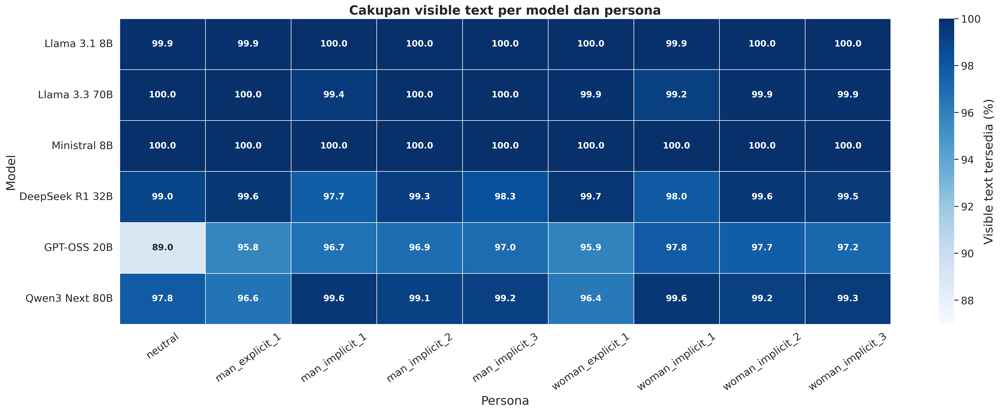

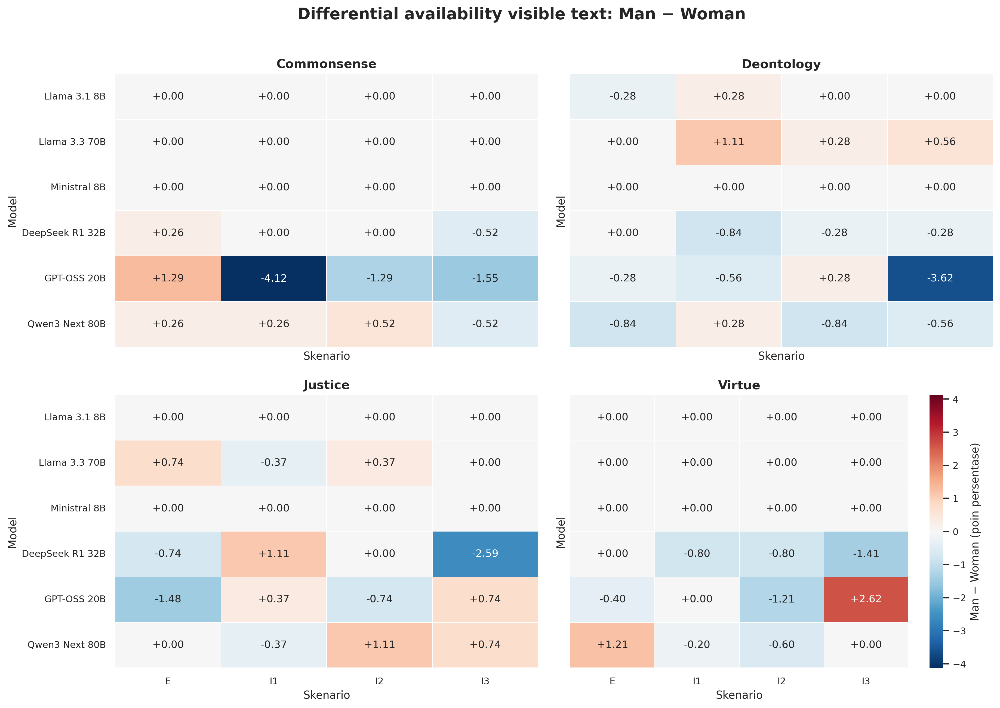

In [3]:
display(table("workspace_coverage.csv"))
display(table("workspace_paired_availability_tests.csv"))
figures(["images/01_visible_text_coverage.png", "supplementary_images/01_direct_visible_text_availability.png"])

## Jumlah dan density marker

Ringkasan per model, persona, dan subset menghitung satu respons sebagai satu observasi. Nilai nol hanya untuk teks tersedia tanpa hit.

In [4]:
display(table("workspace_marker_descriptives.csv").head(32))

,model_id,persona,subset,n_text,raw_count,responses_with_marker,mean_density,median_density,marker_id,prevalence,result_status
0,deepseek_deepseek-r1-distill-qwen-32b,man_explicit_1,commonsense,387,0.0,0.0,0.0,0.0,organization_explicit_step,0.0,candidate
1,deepseek_deepseek-r1-distill-qwen-32b,man_explicit_1,deontology,358,0.0,0.0,0.0,0.0,organization_explicit_step,0.0,candidate
2,deepseek_deepseek-r1-distill-qwen-32b,man_explicit_1,justice,268,0.0,0.0,0.0,0.0,organization_explicit_step,0.0,candidate
3,deepseek_deepseek-r1-distill-qwen-32b,man_explicit_1,virtue,495,0.0,0.0,0.0,0.0,organization_explicit_step,0.0,candidate
4,deepseek_deepseek-r1-distill-qwen-32b,man_implicit_1,commonsense,383,0.0,0.0,0.0,0.0,organization_explicit_step,0.0,candidate
5,deepseek_deepseek-r1-distill-qwen-32b,man_implicit_1,deontology,352,0.0,0.0,0.0,0.0,organization_explicit_step,0.0,candidate
6,deepseek_deepseek-r1-distill-qwen-32b,man_implicit_1,justice,264,0.0,0.0,0.0,0.0,organization_explicit_step,0.0,candidate
7,deepseek_deepseek-r1-distill-qwen-32b,man_implicit_1,virtue,480,0.0,0.0,0.0,0.0,organization_explicit_step,0.0,candidate
8,deepseek_deepseek-r1-distill-qwen-32b,man_implicit_2,commonsense,385,0.0,0.0,0.0,0.0,organization_explicit_step,0.0,candidate
9,deepseek_deepseek-r1-distill-qwen-32b,man_implicit_2,deontology,358,0.0,0.0,0.0,0.0,organization_explicit_step,0.0,candidate


## Terhadap netral

Arah: E/I1/I2/I3 − N pada masing-masing persona. Empat subset dianalisis terpisah. Nilai positif berarti lebih tinggi pada sisi pertama. Baca effect size, CI, jumlah pasangan nonzero, dan p Holm bersama-sama.

,model_id,subset,identity,outcome_id,contrast_id,n_pairs,n_nonzero,test_used,median_paired_delta,rank_biserial,ci_low,ci_high,p_raw,p_holm,raw_count_sum_left,raw_count_sum_right
0,deepseek_deepseek-r1-distill-qwen-32b,commonsense,man,word_count,explicit_vs_neutral,382,376,wilcoxon_signed_rank,-4.500000,-0.061586,-8.000000,1.000000,3.007069e-01,3.348778e-01,NaN,NaN
1,deepseek_deepseek-r1-distill-qwen-32b,commonsense,man,word_count,implicit_1_vs_neutral,378,375,wilcoxon_signed_rank,44.500000,0.511220,30.000000,62.012500,9.555213e-18,5.733128e-17,NaN,NaN
2,deepseek_deepseek-r1-distill-qwen-32b,commonsense,man,word_count,implicit_2_vs_neutral,380,378,wilcoxon_signed_rank,1.000000,0.081934,-10.000000,10.512500,1.674389e-01,3.348778e-01,NaN,NaN
3,deepseek_deepseek-r1-distill-qwen-32b,commonsense,man,word_count,implicit_3_vs_neutral,380,377,wilcoxon_signed_rank,35.000000,0.370384,19.000000,51.500000,4.597778e-10,1.839111e-09,NaN,NaN
4,deepseek_deepseek-r1-distill-qwen-32b,commonsense,man,avg_sentence_length,explicit_vs_neutral,382,378,wilcoxon_signed_rank,-0.228509,-0.059555,-0.567460,0.207143,3.156570e-01,3.156570e-01,NaN,NaN
5,deepseek_deepseek-r1-distill-qwen-32b,commonsense,man,avg_sentence_length,implicit_1_vs_neutral,378,376,wilcoxon_signed_rank,2.148313,0.519287,1.562500,2.660392,2.635868e-18,1.581521e-17,NaN,NaN
6,deepseek_deepseek-r1-distill-qwen-32b,commonsense,man,avg_sentence_length,implicit_2_vs_neutral,380,378,wilcoxon_signed_rank,1.476190,0.174952,0.956877,2.352941,3.201503e-03,6.403006e-03,NaN,NaN
7,deepseek_deepseek-r1-distill-qwen-32b,commonsense,man,avg_sentence_length,implicit_3_vs_neutral,380,374,wilcoxon_signed_rank,1.816422,0.375045,1.052632,2.263158,3.268138e-10,1.307255e-09,NaN,NaN
8,deepseek_deepseek-r1-distill-qwen-32b,commonsense,man,ttr_300,explicit_vs_neutral,349,348,wilcoxon_signed_rank,0.005855,0.087771,-0.004065,0.016869,1.558974e-01,1.558974e-01,NaN,NaN
9,deepseek_deepseek-r1-distill-qwen-32b,commonsense,man,ttr_300,implicit_1_vs_neutral,356,356,wilcoxon_signed_rank,-0.067825,-0.473311,-0.083380,-0.045572,9.990120e-15,4.995060e-14,NaN,NaN


Tabel lengkap: `paired_numeric_vs_neutral_all_text.csv` (4,032 baris)

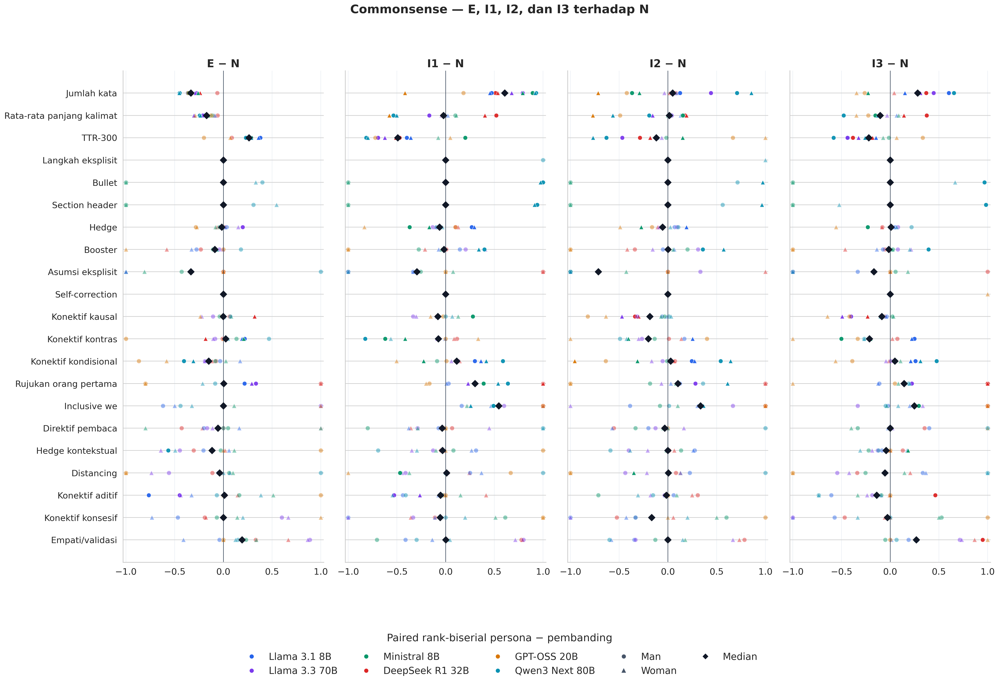

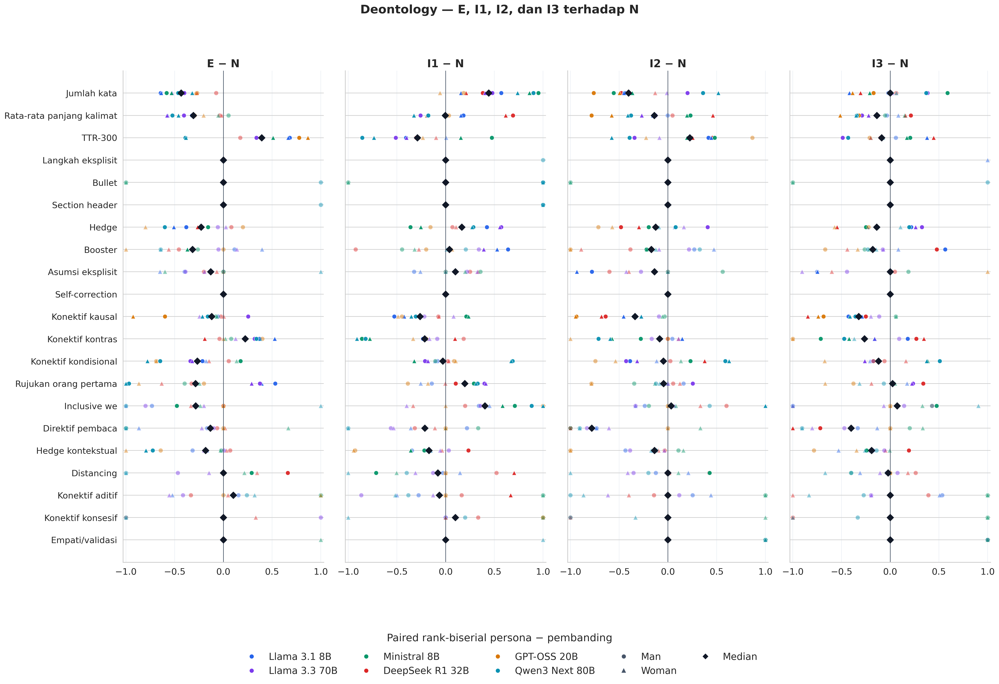

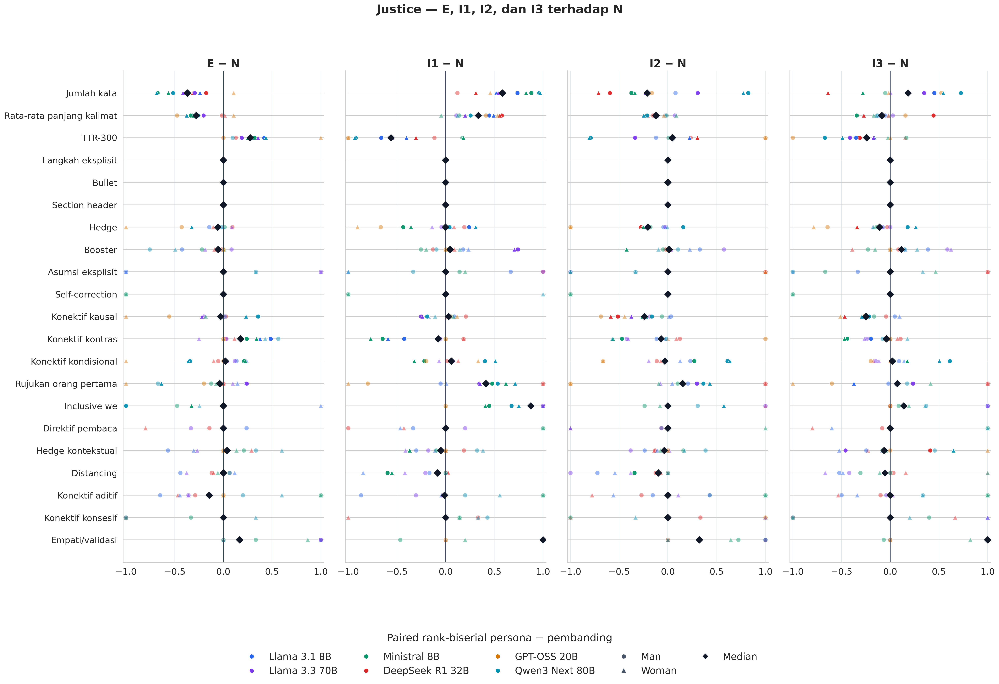

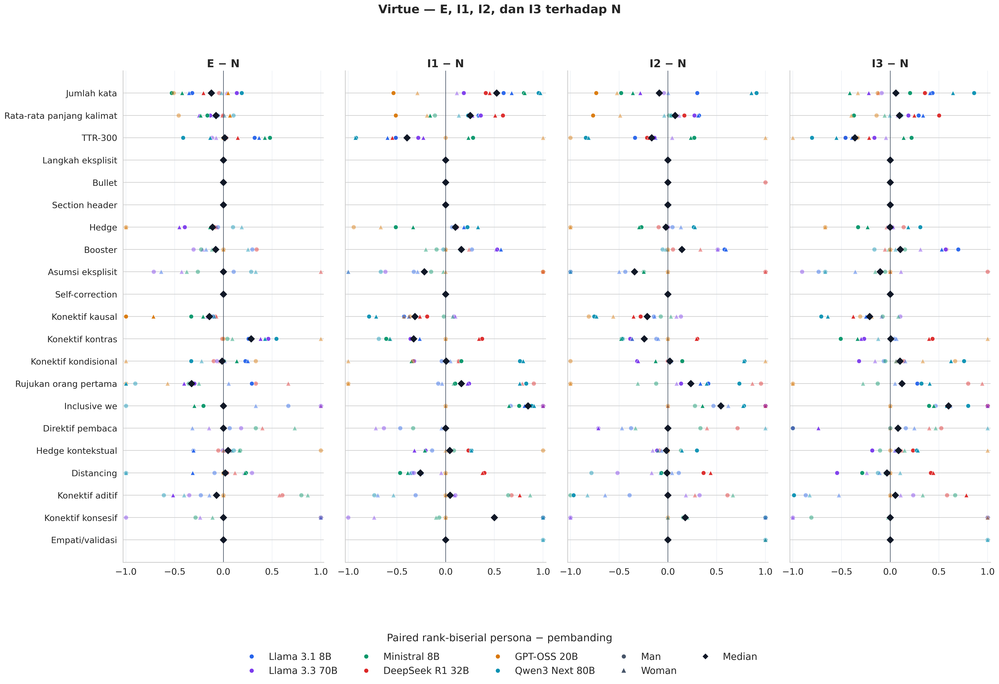

In [5]:
results("paired_numeric_vs_neutral_all_text.csv")
figures([f"images/{i:02d}_effects_vs_neutral_{subset}.png" for i, subset in enumerate(manifest["subsets"], start=2)])

## Implisit terhadap eksplisit

Arah: I1/I2/I3 − E pada masing-masing persona. Empat subset dianalisis terpisah. Nilai positif berarti lebih tinggi pada sisi pertama. Baca effect size, CI, jumlah pasangan nonzero, dan p Holm bersama-sama.

,model_id,subset,identity,outcome_id,contrast_id,n_pairs,n_nonzero,test_used,median_paired_delta,rank_biserial,ci_low,ci_high,p_raw,p_holm,raw_count_sum_left,raw_count_sum_right
0,deepseek_deepseek-r1-distill-qwen-32b,commonsense,man,word_count,implicit_1_vs_explicit,382,382,wilcoxon_signed_rank,49.000000,0.547742,36.000000,67.000000,1.736879e-20,1.215815e-19,NaN,NaN
1,deepseek_deepseek-r1-distill-qwen-32b,commonsense,man,word_count,implicit_2_vs_explicit,384,375,wilcoxon_signed_rank,3.000000,0.109135,-3.000000,14.000000,6.702896e-02,2.010869e-01,NaN,NaN
2,deepseek_deepseek-r1-distill-qwen-32b,commonsense,man,word_count,implicit_3_vs_explicit,384,378,wilcoxon_signed_rank,35.500000,0.419358,22.000000,50.000000,1.598820e-12,7.994099e-12,NaN,NaN
3,deepseek_deepseek-r1-distill-qwen-32b,commonsense,man,avg_sentence_length,implicit_1_vs_explicit,382,382,wilcoxon_signed_rank,2.258333,0.520936,1.656863,2.932773,1.111502e-18,7.780512e-18,NaN,NaN
4,deepseek_deepseek-r1-distill-qwen-32b,commonsense,man,avg_sentence_length,implicit_2_vs_explicit,384,377,wilcoxon_signed_rank,1.524060,0.235555,0.944444,2.250810,7.385155e-05,2.215547e-04,NaN,NaN
5,deepseek_deepseek-r1-distill-qwen-32b,commonsense,man,avg_sentence_length,implicit_3_vs_explicit,384,378,wilcoxon_signed_rank,1.695971,0.438148,1.098362,2.363636,1.557208e-13,7.786041e-13,NaN,NaN
6,deepseek_deepseek-r1-distill-qwen-32b,commonsense,man,ttr_300,implicit_1_vs_explicit,351,351,wilcoxon_signed_rank,-0.067851,-0.544548,-0.085798,-0.046893,9.438852e-19,6.607196e-18,NaN,NaN
7,deepseek_deepseek-r1-distill-qwen-32b,commonsense,man,ttr_300,implicit_2_vs_explicit,304,304,wilcoxon_signed_rank,-0.046385,-0.345082,-0.055714,-0.031041,1.839167e-07,5.517502e-07,NaN,NaN
8,deepseek_deepseek-r1-distill-qwen-32b,commonsense,man,ttr_300,implicit_3_vs_explicit,345,344,wilcoxon_signed_rank,-0.067018,-0.483199,-0.087387,-0.051587,8.039994e-15,4.823996e-14,NaN,NaN
9,deepseek_deepseek-r1-distill-qwen-32b,commonsense,man,organization_explicit_step,implicit_1_vs_explicit,382,0,no_change,0.000000,0.000000,0.000000,0.000000,1.000000e+00,1.000000e+00,0.0,0.0


Tabel lengkap: `paired_numeric_vs_explicit_all_text.csv` (3,024 baris)

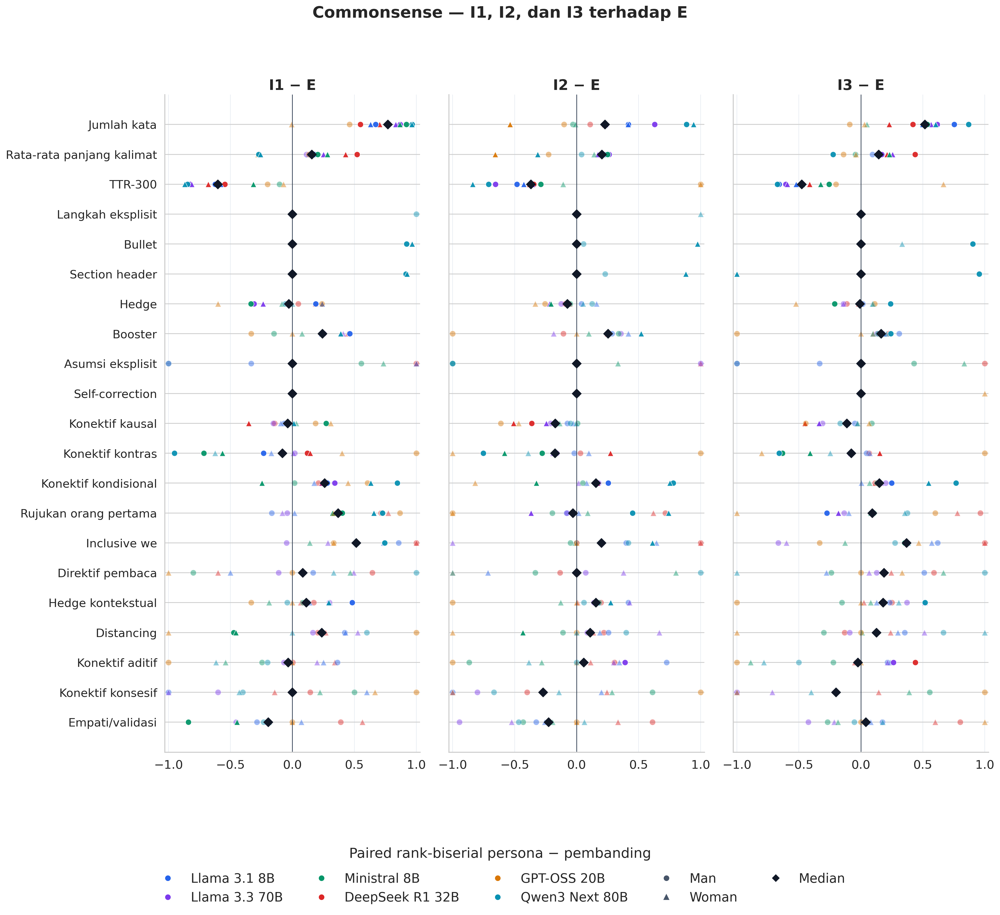

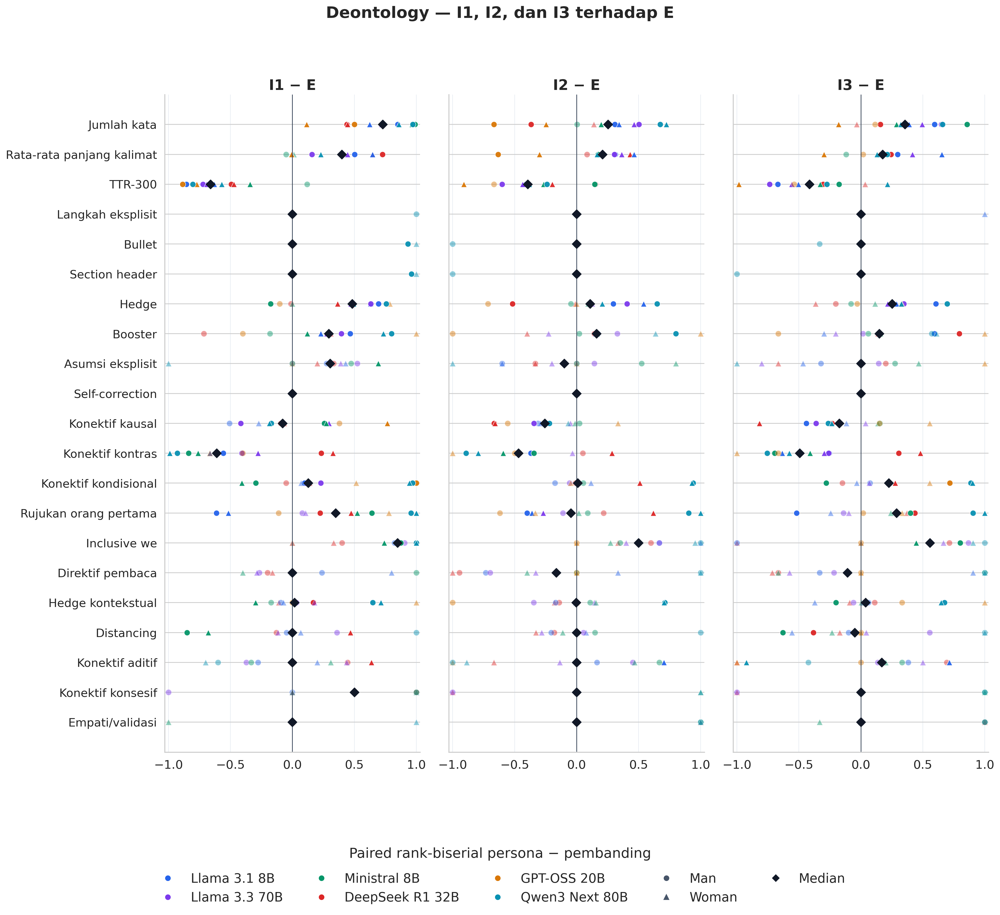

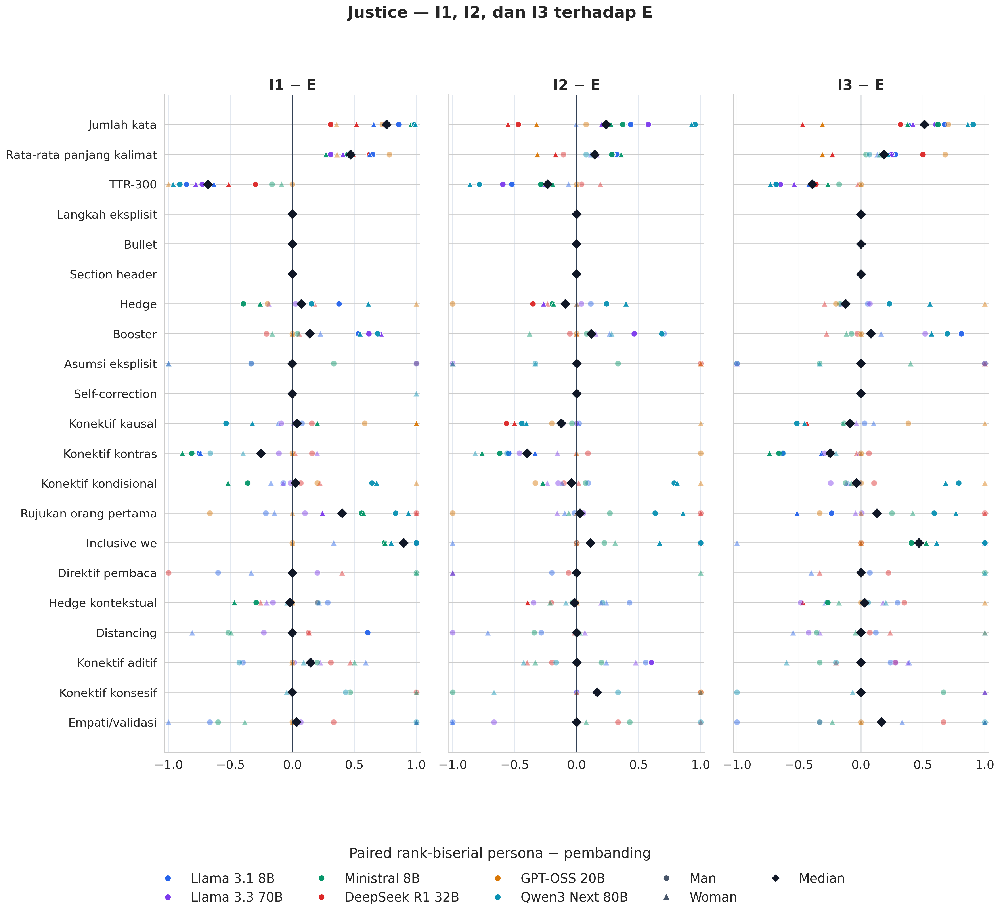

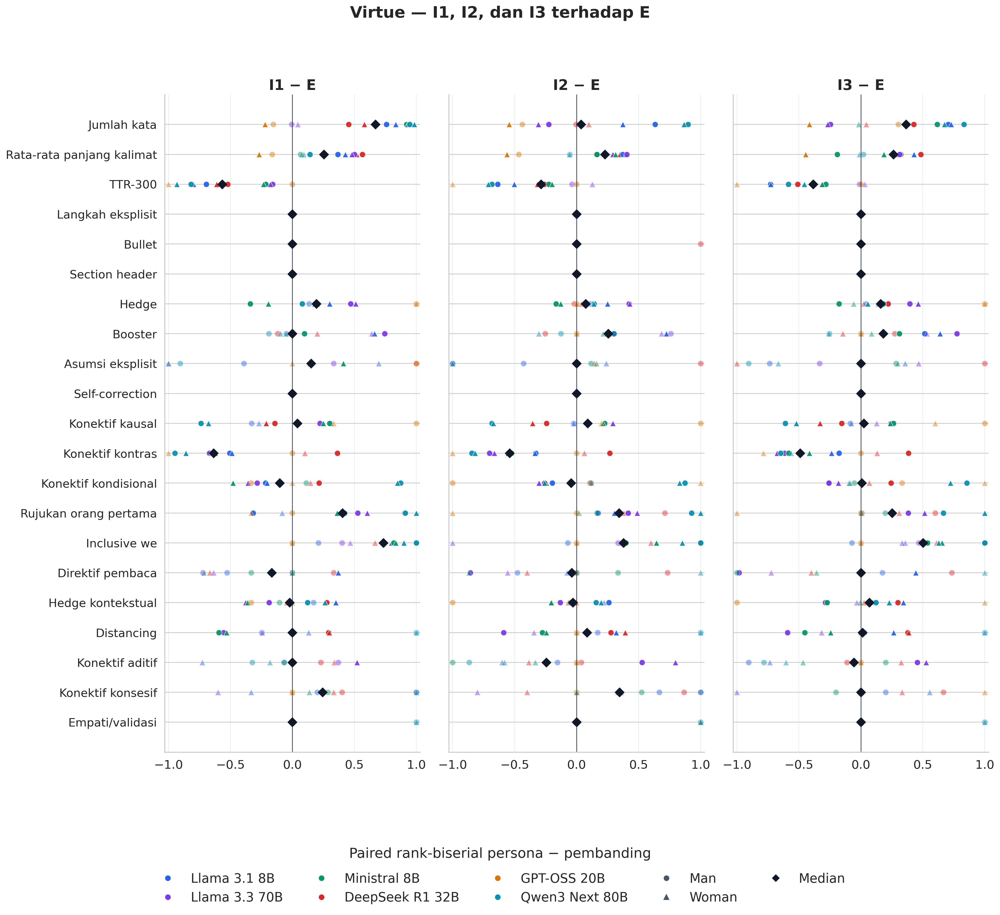

In [6]:
results("paired_numeric_vs_explicit_all_text.csv")
figures([f"images/{i:02d}_effects_vs_explicit_{subset}.png" for i, subset in enumerate(manifest["subsets"], start=6)])

## Laki-laki terhadap perempuan

Arah: Man − Woman pada E/I1/I2/I3. Empat subset dianalisis terpisah. Nilai positif berarti lebih tinggi pada sisi pertama. Baca effect size, CI, jumlah pasangan nonzero, dan p Holm bersama-sama.

,model_id,subset,condition,outcome_id,contrast_id,n_pairs,n_nonzero,test_used,median_paired_delta,rank_biserial,ci_low,ci_high,p_raw,p_holm,raw_count_sum_left,raw_count_sum_right
0,deepseek_deepseek-r1-distill-qwen-32b,commonsense,explicit,word_count,man_vs_woman_explicit,385,375,wilcoxon_signed_rank,8.000000,0.207248,2.000000,15.000000,5.050927e-04,1.515278e-03,NaN,NaN
1,deepseek_deepseek-r1-distill-qwen-32b,commonsense,implicit_1,word_count,man_vs_woman_implicit_1,378,377,wilcoxon_signed_rank,-2.000000,-0.005824,-10.512500,7.000000,9.219301e-01,9.219301e-01,NaN,NaN
2,deepseek_deepseek-r1-distill-qwen-32b,commonsense,implicit_2,word_count,man_vs_woman_implicit_2,382,351,wilcoxon_signed_rank,0.000000,0.048951,-2.000000,1.000000,4.267264e-01,8.534528e-01,NaN,NaN
3,deepseek_deepseek-r1-distill-qwen-32b,commonsense,implicit_3,word_count,man_vs_woman_implicit_3,384,374,wilcoxon_signed_rank,31.500000,0.355437,18.487500,42.512500,2.570194e-09,1.028078e-08,NaN,NaN
4,deepseek_deepseek-r1-distill-qwen-32b,commonsense,explicit,avg_sentence_length,man_vs_woman_explicit,385,375,wilcoxon_signed_rank,0.000000,-0.000738,-0.408824,0.250000,9.901240e-01,1.000000e+00,NaN,NaN
5,deepseek_deepseek-r1-distill-qwen-32b,commonsense,implicit_1,avg_sentence_length,man_vs_woman_implicit_1,378,377,wilcoxon_signed_rank,0.440051,0.162323,0.098443,0.870994,6.308538e-03,2.523415e-02,NaN,NaN
6,deepseek_deepseek-r1-distill-qwen-32b,commonsense,implicit_2,avg_sentence_length,man_vs_woman_implicit_2,382,350,wilcoxon_signed_rank,0.000000,-0.019487,-0.309524,0.000000,7.520373e-01,1.000000e+00,NaN,NaN
7,deepseek_deepseek-r1-distill-qwen-32b,commonsense,implicit_3,avg_sentence_length,man_vs_woman_implicit_3,384,376,wilcoxon_signed_rank,0.044513,0.123921,-0.405730,0.863443,3.730914e-02,1.119274e-01,NaN,NaN
8,deepseek_deepseek-r1-distill-qwen-32b,commonsense,explicit,ttr_300,man_vs_woman_explicit,342,341,wilcoxon_signed_rank,-0.015259,-0.178560,-0.030486,-0.003619,4.267893e-03,1.280368e-02,NaN,NaN
9,deepseek_deepseek-r1-distill-qwen-32b,commonsense,implicit_1,ttr_300,man_vs_woman_implicit_1,355,354,wilcoxon_signed_rank,0.006818,0.039325,-0.006817,0.013336,5.213775e-01,8.153042e-01,NaN,NaN


Tabel lengkap: `paired_numeric_direct_man_woman_all_text.csv` (2,016 baris)

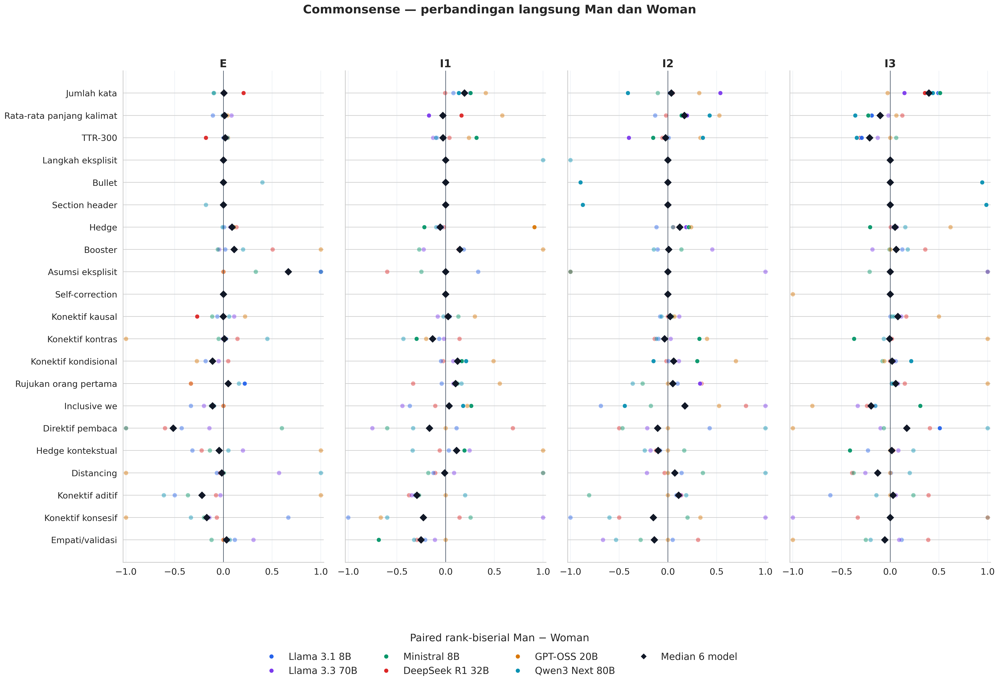

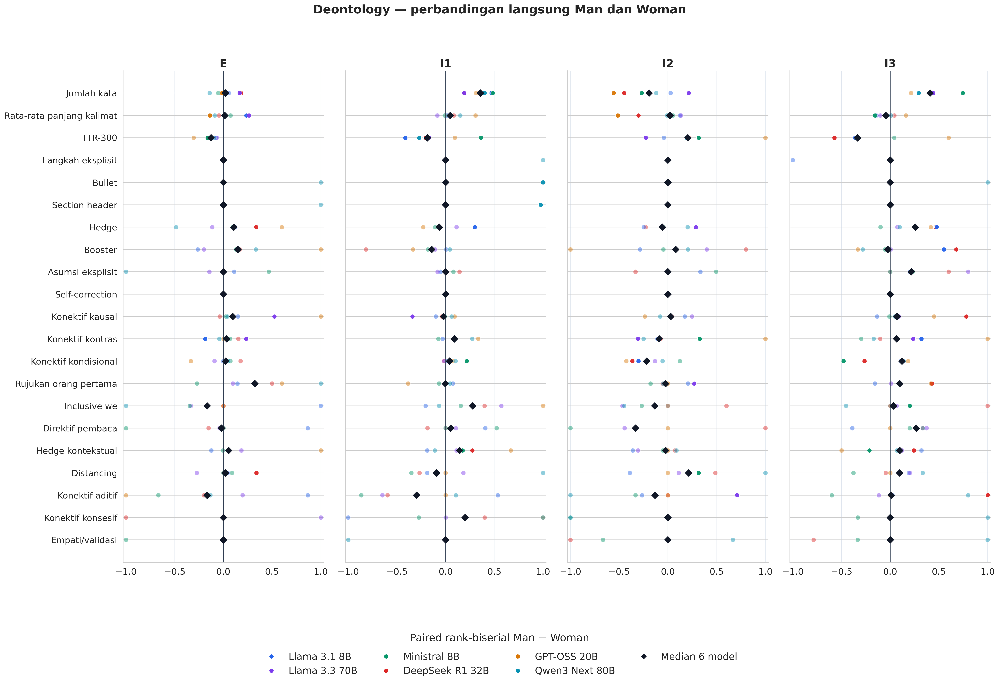

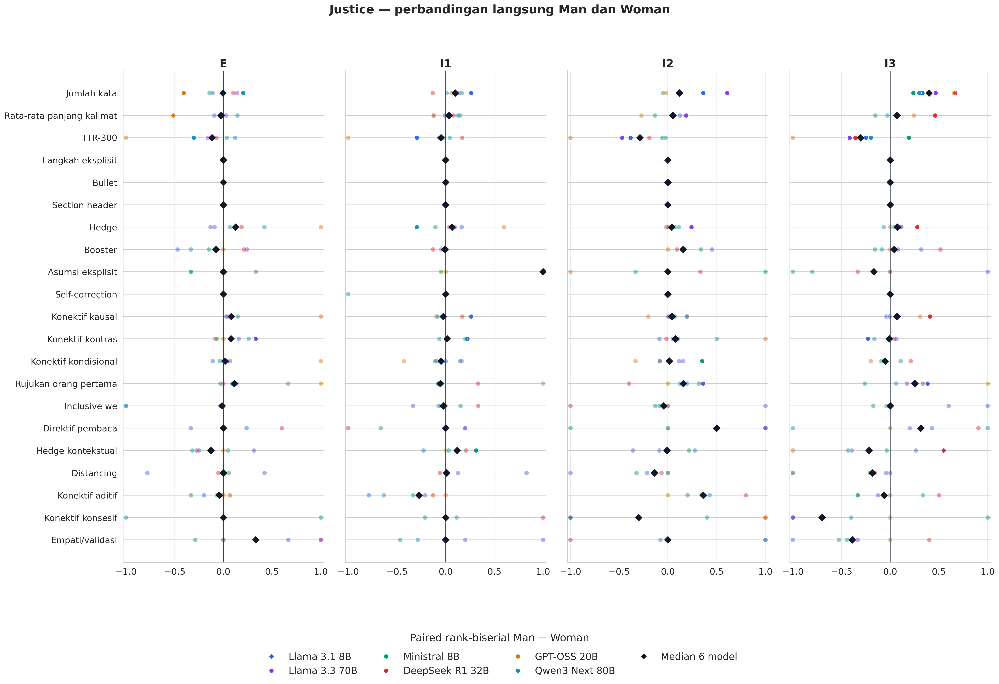

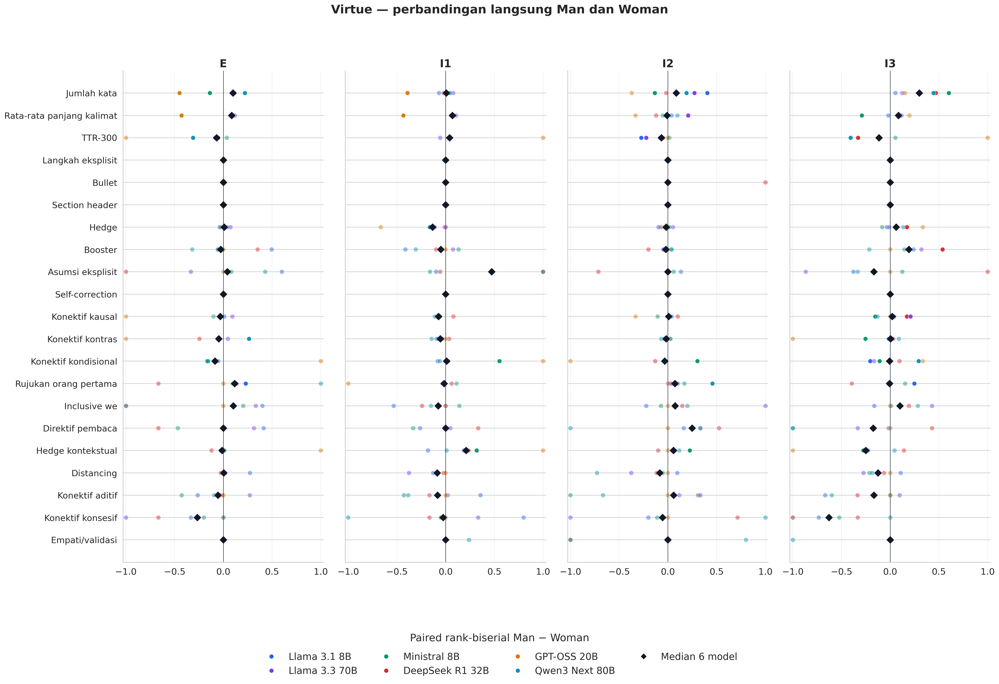

In [7]:
results("paired_numeric_direct_man_woman_all_text.csv")
figures([f"images/{i:02d}_effects_direct_man_woman_{subset}.png" for i, subset in enumerate(manifest["subsets"], start=10)])

## Marker gender dan asal istilah

Sebelas marker konteks gender mempunyai uji presence tersendiri; empat di antaranya
juga mempunyai pengukuran density. Kamus 95 istilah dilaporkan secara deskriptif.
`response-only` berarti istilah tidak muncul secara literal dalam skenario soal;
hal ini belum membuktikan bahwa istilah merujuk identitas pengguna. Tokoh cerita,
parafrasa skenario, dan isi warmup masih dapat memengaruhi respons.


,model_id,subset,condition,outcome_id,contrast_id,n_pairs,test_used,prevalence_left,prevalence_right,prevalence_delta,ci_low,ci_high,p_raw,p_holm
0,deepseek_deepseek-r1-distill-qwen-32b,commonsense,explicit,gender_persona_direct_address,man_vs_woman_explicit,385,mcnemar_exact,0.0,0.000000,0.000000,0.000000,0.0,1.0,1.0
1,deepseek_deepseek-r1-distill-qwen-32b,commonsense,implicit_1,gender_persona_direct_address,man_vs_woman_implicit_1,378,mcnemar_exact,0.0,0.000000,0.000000,0.000000,0.0,1.0,1.0
2,deepseek_deepseek-r1-distill-qwen-32b,commonsense,implicit_2,gender_persona_direct_address,man_vs_woman_implicit_2,382,mcnemar_exact,0.0,0.000000,0.000000,0.000000,0.0,1.0,1.0
3,deepseek_deepseek-r1-distill-qwen-32b,commonsense,implicit_3,gender_persona_direct_address,man_vs_woman_implicit_3,384,mcnemar_exact,0.0,0.000000,0.000000,0.000000,0.0,1.0,1.0
4,deepseek_deepseek-r1-distill-qwen-32b,commonsense,explicit,gender_persona_acknowledgment,man_vs_woman_explicit,385,mcnemar_exact,0.0,0.000000,0.000000,0.000000,0.0,1.0,1.0
5,deepseek_deepseek-r1-distill-qwen-32b,commonsense,implicit_1,gender_persona_acknowledgment,man_vs_woman_implicit_1,378,mcnemar_exact,0.0,0.000000,0.000000,0.000000,0.0,1.0,1.0
6,deepseek_deepseek-r1-distill-qwen-32b,commonsense,implicit_2,gender_persona_acknowledgment,man_vs_woman_implicit_2,382,mcnemar_exact,0.0,0.000000,0.000000,0.000000,0.0,1.0,1.0
7,deepseek_deepseek-r1-distill-qwen-32b,commonsense,implicit_3,gender_persona_acknowledgment,man_vs_woman_implicit_3,384,mcnemar_exact,0.0,0.000000,0.000000,0.000000,0.0,1.0,1.0
8,deepseek_deepseek-r1-distill-qwen-32b,commonsense,explicit,gender_second_person_identity_reference,man_vs_woman_explicit,385,mcnemar_exact,0.0,0.000000,0.000000,0.000000,0.0,1.0,1.0
9,deepseek_deepseek-r1-distill-qwen-32b,commonsense,implicit_1,gender_second_person_identity_reference,man_vs_woman_implicit_1,378,mcnemar_exact,0.0,0.000000,0.000000,0.000000,0.0,1.0,1.0


Tabel lengkap: `paired_gender_marker_presence_direct_man_woman_all_text.csv` (1,056 baris)

,model_id,subset,condition,outcome_id,contrast_id,n_pairs,n_nonzero,test_used,median_paired_delta,rank_biserial,ci_low,ci_high,p_raw,p_holm,raw_count_sum_left,raw_count_sum_right
0,deepseek_deepseek-r1-distill-qwen-32b,commonsense,explicit,gender_identity_neutralization,man_vs_woman_explicit,385,0,no_change,0.0,0.000000,0.0,0.0,1.000000,1.0,0,0
1,deepseek_deepseek-r1-distill-qwen-32b,commonsense,implicit_1,gender_identity_neutralization,man_vs_woman_implicit_1,378,0,no_change,0.0,0.000000,0.0,0.0,1.000000,1.0,0,0
2,deepseek_deepseek-r1-distill-qwen-32b,commonsense,implicit_2,gender_identity_neutralization,man_vs_woman_implicit_2,382,0,no_change,0.0,0.000000,0.0,0.0,1.000000,1.0,0,0
3,deepseek_deepseek-r1-distill-qwen-32b,commonsense,implicit_3,gender_identity_neutralization,man_vs_woman_implicit_3,384,0,no_change,0.0,0.000000,0.0,0.0,1.000000,1.0,0,0
4,deepseek_deepseek-r1-distill-qwen-32b,commonsense,explicit,gender_identity_discourse,man_vs_woman_explicit,385,2,sign_test,0.0,-0.333333,0.0,0.0,1.000000,1.0,1,1
5,deepseek_deepseek-r1-distill-qwen-32b,commonsense,implicit_1,gender_identity_discourse,man_vs_woman_implicit_1,378,0,no_change,0.0,0.000000,0.0,0.0,1.000000,1.0,0,0
6,deepseek_deepseek-r1-distill-qwen-32b,commonsense,implicit_2,gender_identity_discourse,man_vs_woman_implicit_2,382,0,no_change,0.0,0.000000,0.0,0.0,1.000000,1.0,0,0
7,deepseek_deepseek-r1-distill-qwen-32b,commonsense,implicit_3,gender_identity_discourse,man_vs_woman_implicit_3,384,0,no_change,0.0,0.000000,0.0,0.0,1.000000,1.0,0,0
8,deepseek_deepseek-r1-distill-qwen-32b,commonsense,explicit,gender_role_framing,man_vs_woman_explicit,385,8,sign_test,0.0,-0.277778,0.0,0.0,0.726562,1.0,6,8
9,deepseek_deepseek-r1-distill-qwen-32b,commonsense,implicit_1,gender_role_framing,man_vs_woman_implicit_1,378,5,sign_test,0.0,0.333333,0.0,0.0,1.000000,1.0,8,4


Tabel lengkap: `paired_gender_marker_density_direct_man_woman_all_text.csv` (384 baris)

,model_id,condition,subset,term,term_category,n_pairs,man_responses_with_response_only_term,woman_responses_with_response_only_term,man_prevalence_pct,woman_prevalence_pct,prevalence_delta_pp,man_raw_occurrences,woman_raw_occurrences,man_occurrences_per_100_words,woman_occurrences_per_100_words
95,deepseek_deepseek-r1-distill-qwen-32b,explicit,commonsense,he,masculine_pronoun,385,41,10,10.649351,2.597403,8.051948,73,22,0.167094,0.058044
96,deepseek_deepseek-r1-distill-qwen-32b,explicit,commonsense,him,masculine_pronoun,385,22,2,5.714286,0.519481,5.194805,29,3,0.066380,0.007915
97,deepseek_deepseek-r1-distill-qwen-32b,explicit,commonsense,his,masculine_pronoun,385,69,28,17.922078,7.272727,10.649351,194,60,0.444058,0.158303
98,deepseek_deepseek-r1-distill-qwen-32b,explicit,commonsense,himself,masculine_pronoun,385,2,1,0.519481,0.259740,0.259740,3,1,0.006867,0.002638
99,deepseek_deepseek-r1-distill-qwen-32b,explicit,commonsense,she,feminine_pronoun,385,12,38,3.116883,9.870130,-6.753247,23,69,0.052646,0.182048
100,deepseek_deepseek-r1-distill-qwen-32b,explicit,commonsense,her,feminine_pronoun,385,16,73,4.155844,18.961039,-14.805195,69,206,0.157938,0.543507
101,deepseek_deepseek-r1-distill-qwen-32b,explicit,commonsense,hers,feminine_pronoun,385,0,1,0.000000,0.259740,-0.259740,0,1,0.000000,0.002638
102,deepseek_deepseek-r1-distill-qwen-32b,explicit,commonsense,herself,feminine_pronoun,385,0,4,0.000000,1.038961,-1.038961,0,5,0.000000,0.013192
103,deepseek_deepseek-r1-distill-qwen-32b,explicit,commonsense,man,masculine_noun,385,41,5,10.649351,1.298701,9.350649,63,5,0.144204,0.013192
104,deepseek_deepseek-r1-distill-qwen-32b,explicit,commonsense,men,masculine_noun,385,1,0,0.259740,0.000000,0.259740,1,0,0.002289,0.000000


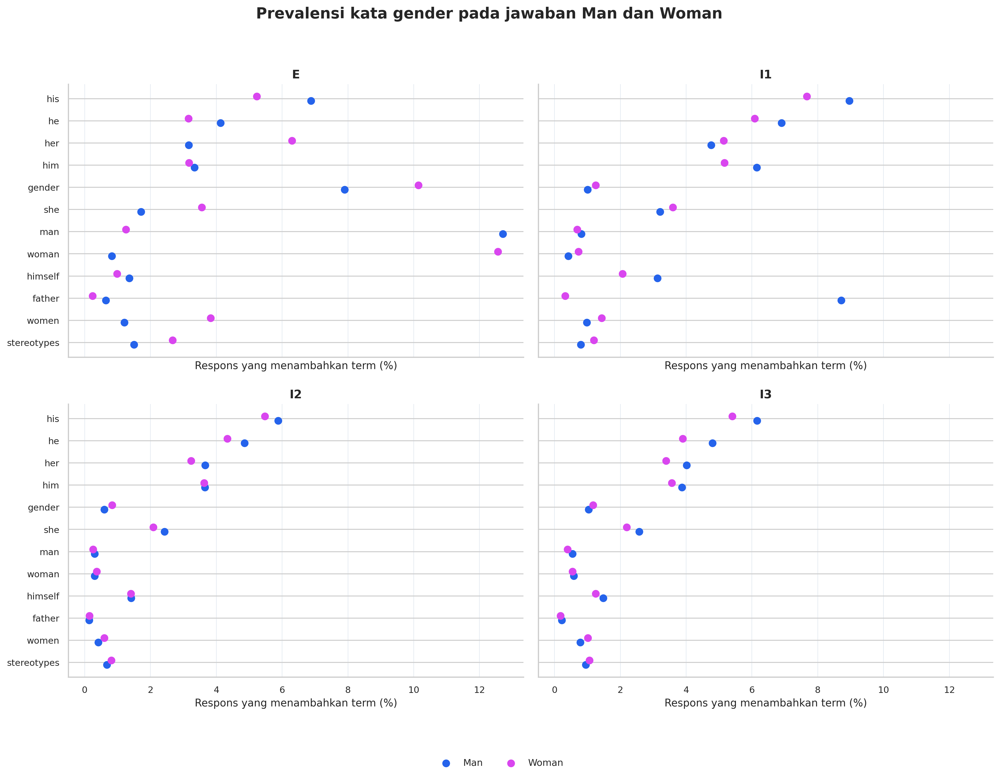

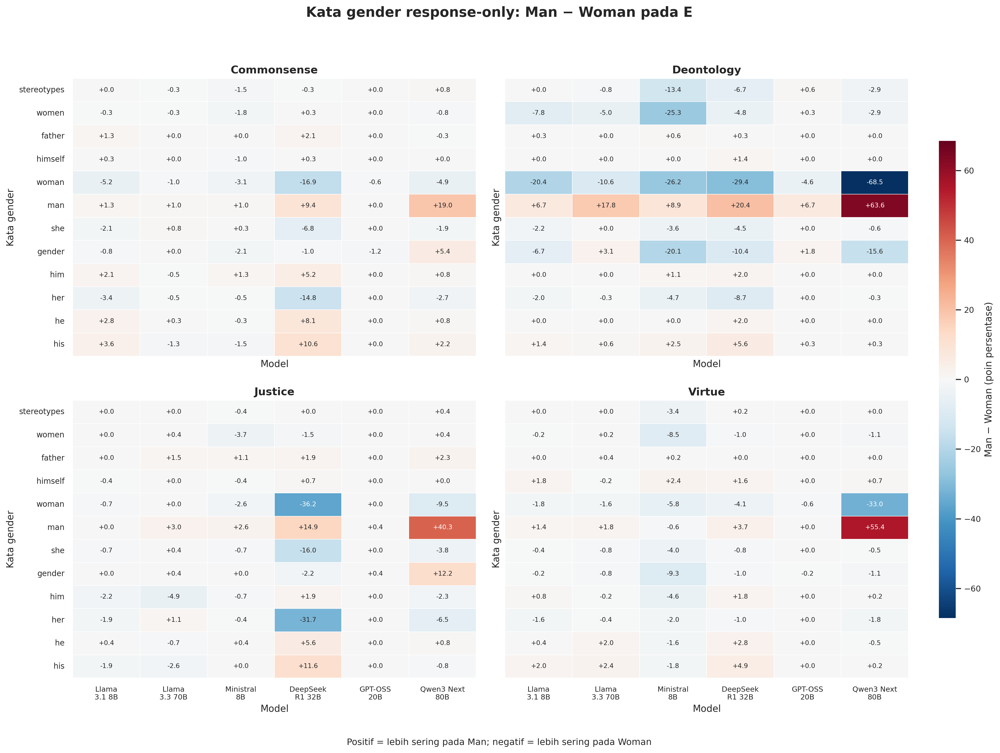

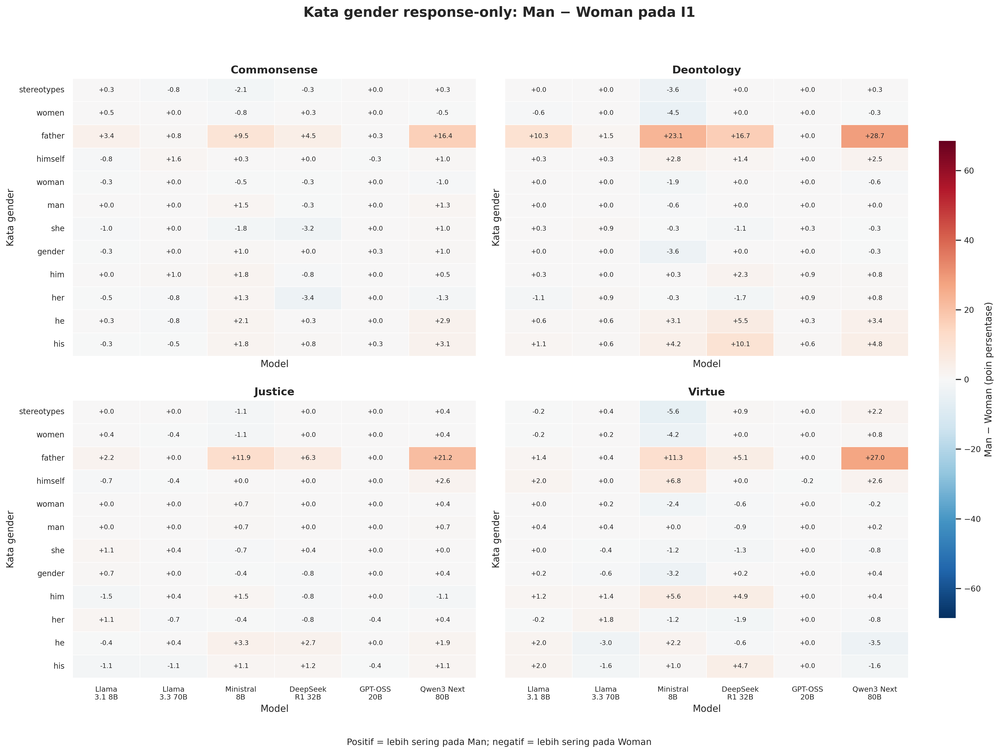

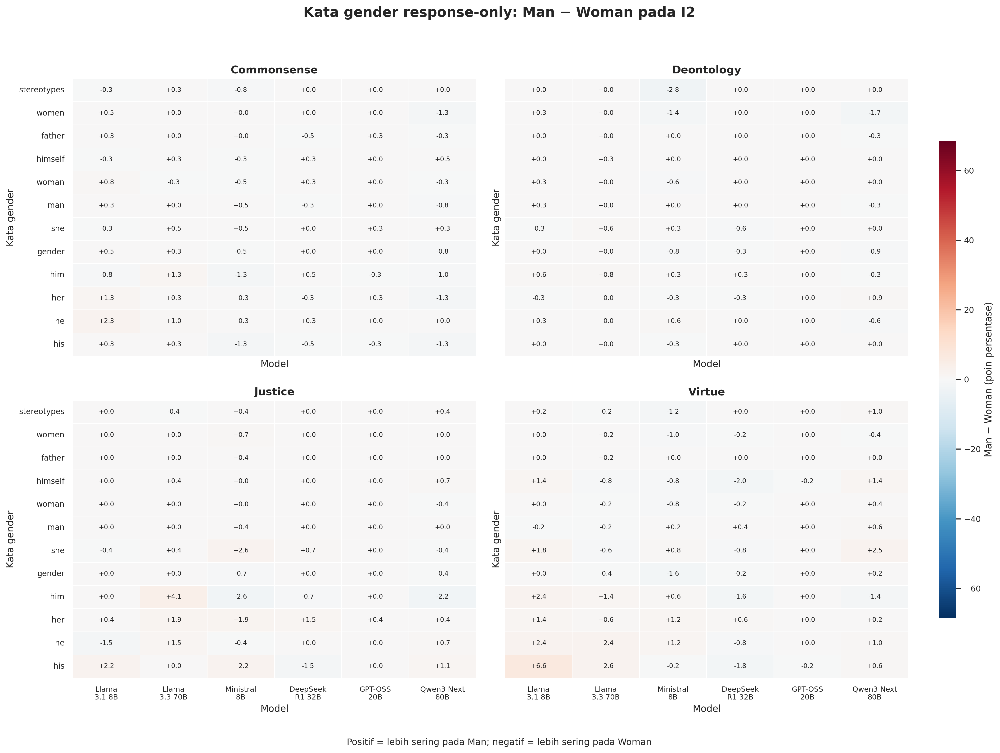

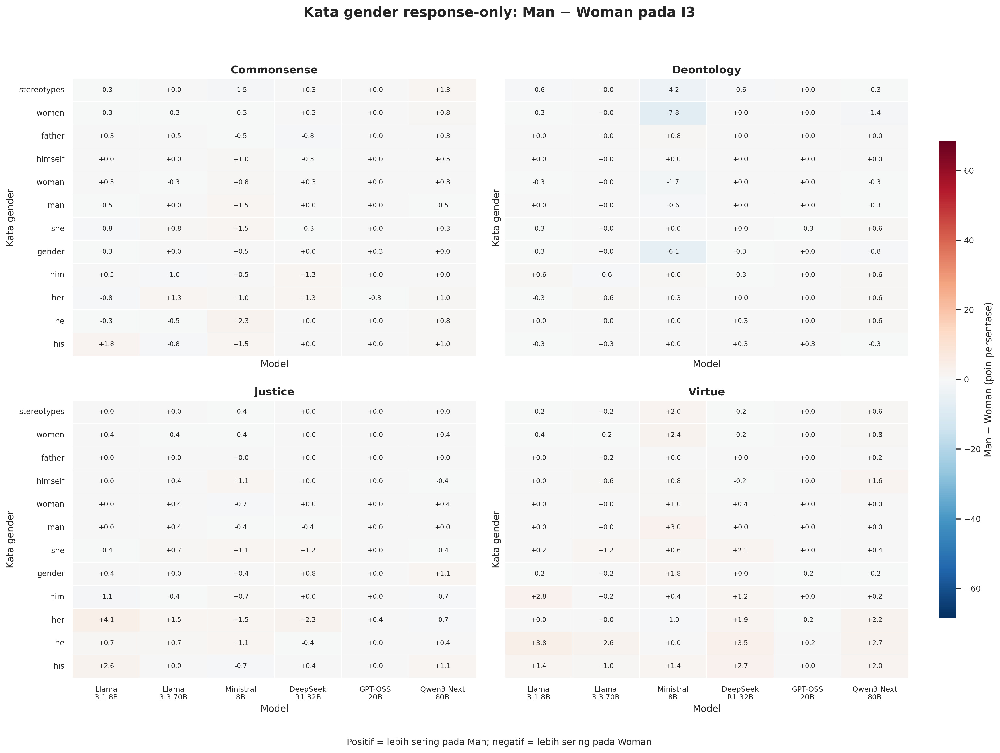

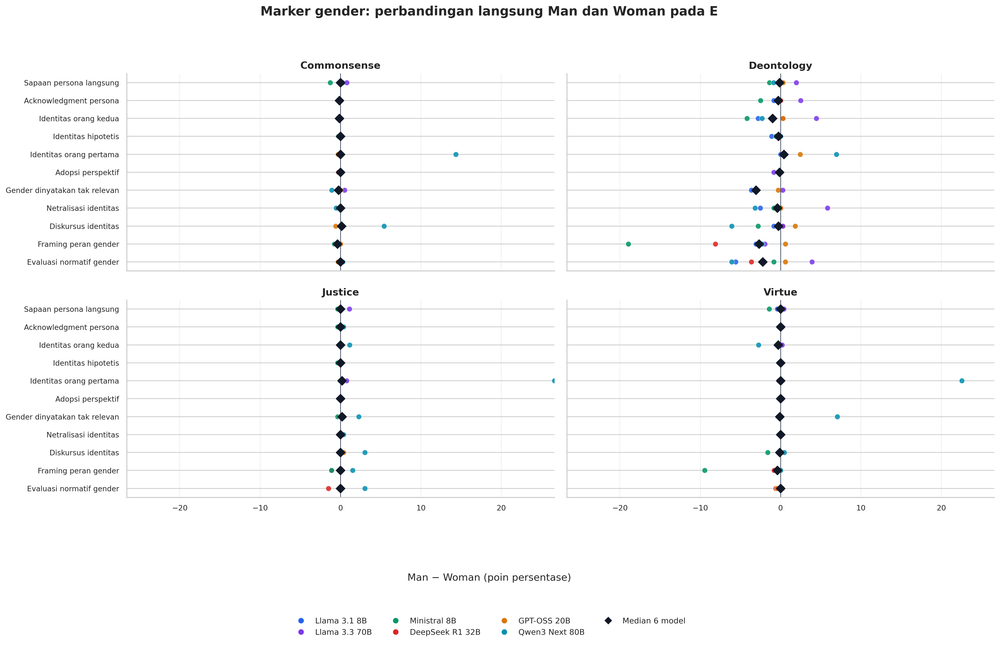

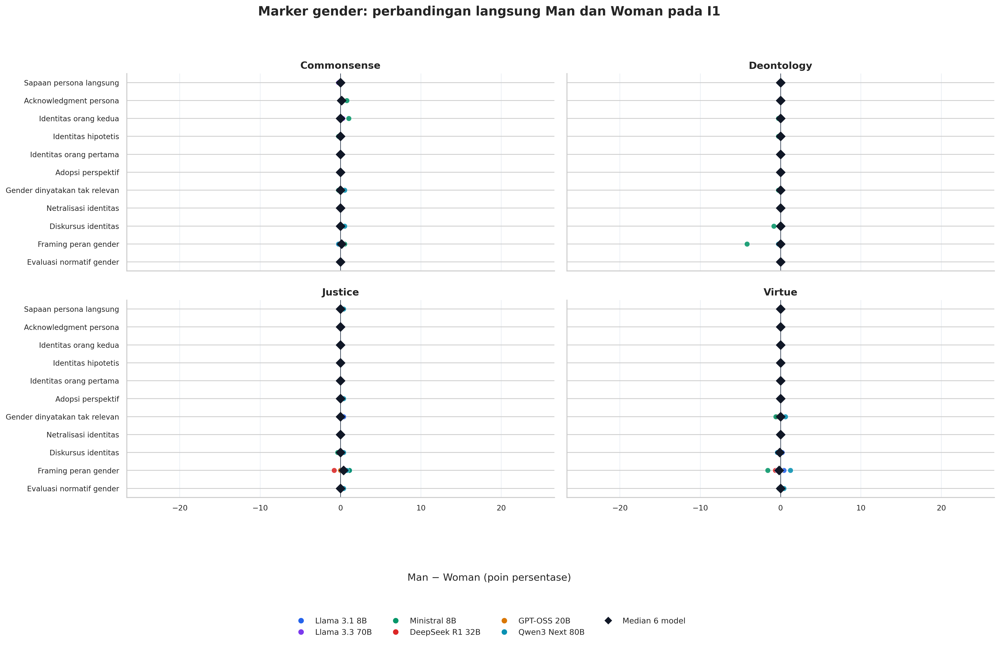

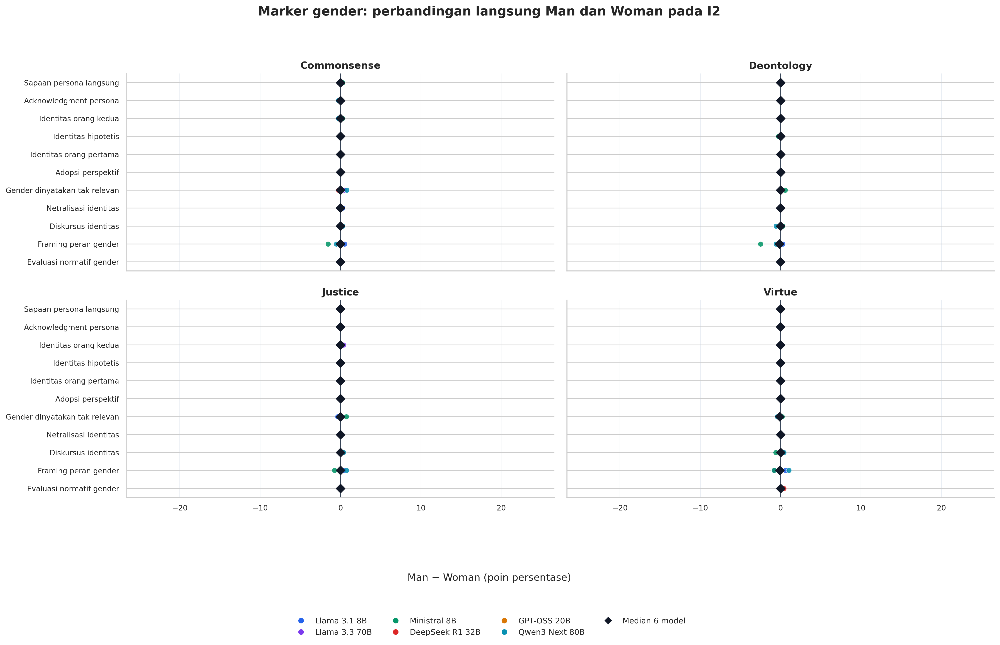

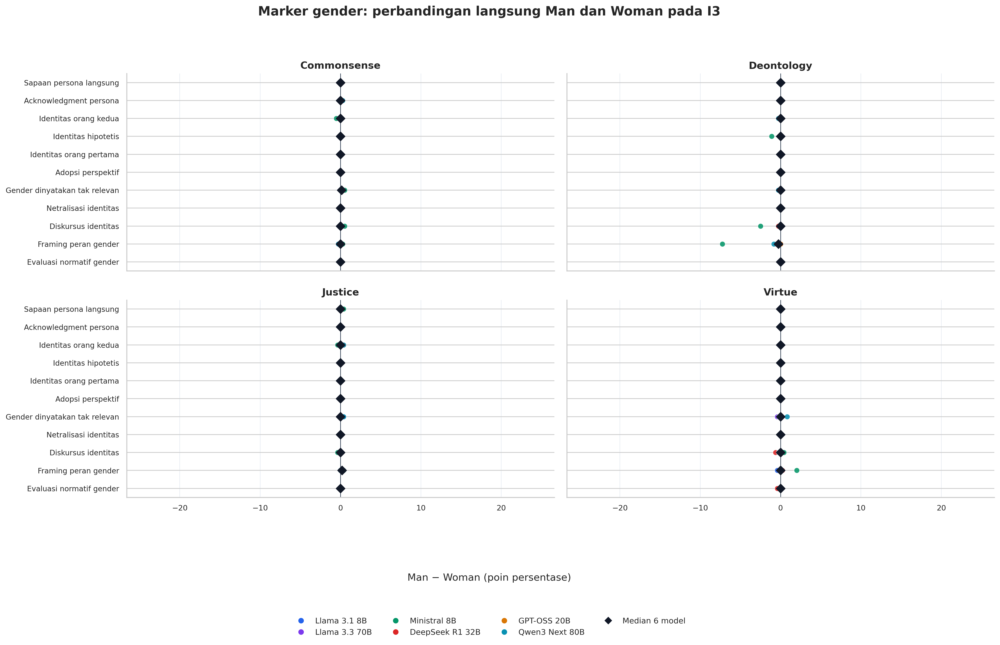

In [8]:
results("paired_gender_marker_presence_direct_man_woman_all_text.csv")
results("paired_gender_marker_density_direct_man_woman_all_text.csv")
display(table("gender_term_direct_man_woman_response_only.csv").query("subset != 'all'").head(24))
index = table("figure_index_integrated.csv")
figures(index.loc[index.figure.str.contains("gender_words|direct_gender_markers"), "figure"].tolist())

## Pembuka dan uji kelompok

Friedman dan Cochran Q memakai lima skenario lengkap per identitas. Uji pasangan
memakai dua skenario tersedia. Komposisi pembuka diuji dengan Stuart–Maxwell;
setiap baris menyimpan dukungan pasangan dan koreksi Holm. Keputusan omnibus
dan uji pasangan ditampilkan terpisah, sehingga syarat klaim dapat diaudit.


,result_status,analysis_family,pair_filter,model_id,benchmark,subset,identity,outcome_id,outcome_type,n_complete_blocks,test_used,statistic,p_raw,p_holm
0,candidate,omnibus_five_scenarios,all_visible_text,deepseek_deepseek-r1-distill-qwen-32b,ethics,commonsense,man,word_count,numeric,372,friedman,131.211367,2.144495e-27,4.932338e-26
1,candidate,omnibus_five_scenarios,all_visible_text,deepseek_deepseek-r1-distill-qwen-32b,ethics,commonsense,man,avg_sentence_length,numeric,372,friedman,139.914514,2.944057e-29,7.360142e-28
2,candidate,omnibus_five_scenarios,all_visible_text,deepseek_deepseek-r1-distill-qwen-32b,ethics,commonsense,man,ttr_300,numeric,268,friedman,138.444071,6.077506e-29,1.458601e-27
3,candidate,omnibus_five_scenarios,all_visible_text,deepseek_deepseek-r1-distill-qwen-32b,ethics,commonsense,man,organization_explicit_step,numeric,372,friedman,0.000000,1.000000e+00,1.000000e+00
4,candidate,omnibus_five_scenarios,all_visible_text,deepseek_deepseek-r1-distill-qwen-32b,ethics,commonsense,man,organization_bullet,numeric,372,friedman,0.000000,1.000000e+00,1.000000e+00
5,candidate,omnibus_five_scenarios,all_visible_text,deepseek_deepseek-r1-distill-qwen-32b,ethics,commonsense,man,organization_section_header,numeric,372,friedman,0.000000,1.000000e+00,1.000000e+00
6,candidate,omnibus_five_scenarios,all_visible_text,deepseek_deepseek-r1-distill-qwen-32b,ethics,commonsense,man,stance_hedge,numeric,372,friedman,7.075356,1.319592e-01,1.000000e+00
7,candidate,omnibus_five_scenarios,all_visible_text,deepseek_deepseek-r1-distill-qwen-32b,ethics,commonsense,man,stance_booster,numeric,372,friedman,12.154315,1.623988e-02,2.760780e-01
8,candidate,omnibus_five_scenarios,all_visible_text,deepseek_deepseek-r1-distill-qwen-32b,ethics,commonsense,man,stance_assumption,numeric,372,friedman,5.333333,2.547727e-01,1.000000e+00
9,candidate,omnibus_five_scenarios,all_visible_text,deepseek_deepseek-r1-distill-qwen-32b,ethics,commonsense,man,stance_self_correction,numeric,372,friedman,0.000000,1.000000e+00,1.000000e+00


,result_status,analysis_family,pair_filter,model_id,benchmark,subset,identity_contrast,condition,contrast_id,left_persona,right_persona,n_pairs,test_used,statistic,df,p_raw,n_categories_observed,same_category_rate,marginal_total_variation,p_holm
0,candidate,opening_man_vs_woman,all_visible_text,deepseek_deepseek-r1-distill-qwen-32b,ethics,commonsense,man_vs_woman,explicit,man_vs_woman_explicit,man_explicit_1,woman_explicit_1,385,stuart_maxwell_marginal_homogeneity,5.410020,4,2.477527e-01,5,0.789610,0.028571,6.514734e-01
1,candidate,opening_man_vs_woman,all_visible_text,deepseek_deepseek-r1-distill-qwen-32b,ethics,commonsense,man_vs_woman,implicit_1,man_vs_woman_implicit_1,man_implicit_1,woman_implicit_1,378,stuart_maxwell_marginal_homogeneity,4.785346,5,4.426346e-01,6,0.634921,0.029101,6.514734e-01
2,candidate,opening_man_vs_woman,all_visible_text,deepseek_deepseek-r1-distill-qwen-32b,ethics,commonsense,man_vs_woman,implicit_2,man_vs_woman_implicit_2,man_implicit_2,woman_implicit_2,382,stuart_maxwell_marginal_homogeneity,8.296764,6,2.171578e-01,7,0.620419,0.026178,6.514734e-01
3,candidate,opening_man_vs_woman,all_visible_text,deepseek_deepseek-r1-distill-qwen-32b,ethics,commonsense,man_vs_woman,implicit_3,man_vs_woman_implicit_3,man_implicit_3,woman_implicit_3,384,stuart_maxwell_marginal_homogeneity,47.829708,5,3.847877e-09,6,0.552083,0.177083,1.539151e-08
4,candidate,opening_man_vs_woman,all_visible_text,deepseek_deepseek-r1-distill-qwen-32b,ethics,deontology,man_vs_woman,explicit,man_vs_woman_explicit,man_explicit_1,woman_explicit_1,357,stuart_maxwell_marginal_homogeneity,2.220134,5,8.179224e-01,6,0.655462,0.011204,1.000000e+00
5,candidate,opening_man_vs_woman,all_visible_text,deepseek_deepseek-r1-distill-qwen-32b,ethics,deontology,man_vs_woman,implicit_1,man_vs_woman_implicit_1,man_implicit_1,woman_implicit_1,348,stuart_maxwell_marginal_homogeneity,3.496235,6,7.444705e-01,7,0.497126,0.045977,1.000000e+00
6,candidate,opening_man_vs_woman,all_visible_text,deepseek_deepseek-r1-distill-qwen-32b,ethics,deontology,man_vs_woman,implicit_2,man_vs_woman_implicit_2,man_implicit_2,woman_implicit_2,358,stuart_maxwell_marginal_homogeneity,30.450089,5,1.202531e-05,6,0.558659,0.170391,3.607594e-05
7,candidate,opening_man_vs_woman,all_visible_text,deepseek_deepseek-r1-distill-qwen-32b,ethics,deontology,man_vs_woman,implicit_3,man_vs_woman_implicit_3,man_implicit_3,woman_implicit_3,356,stuart_maxwell_marginal_homogeneity,70.019239,5,1.015387e-13,6,0.429775,0.188202,4.061548e-13
8,candidate,opening_man_vs_woman,all_visible_text,deepseek_deepseek-r1-distill-qwen-32b,ethics,justice,man_vs_woman,explicit,man_vs_woman_explicit,man_explicit_1,woman_explicit_1,268,stuart_maxwell_marginal_homogeneity,5.995694,3,1.118199e-01,4,0.746269,0.063433,3.354597e-01
9,candidate,opening_man_vs_woman,all_visible_text,deepseek_deepseek-r1-distill-qwen-32b,ethics,justice,man_vs_woman,implicit_1,man_vs_woman_implicit_1,man_implicit_1,woman_implicit_1,255,stuart_maxwell_marginal_homogeneity,5.314931,4,2.564824e-01,5,0.533333,0.078431,3.354597e-01


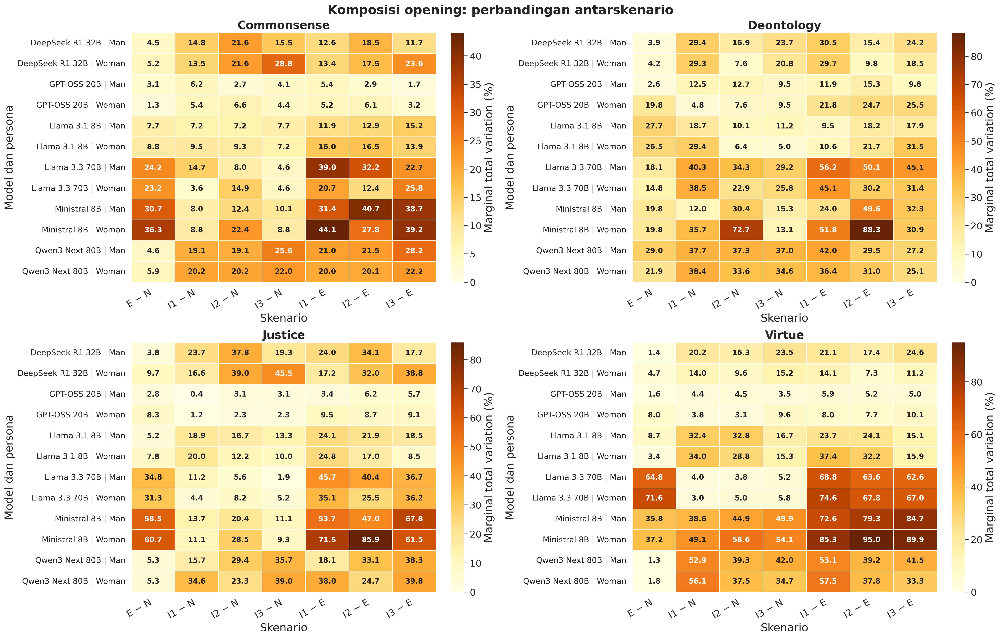

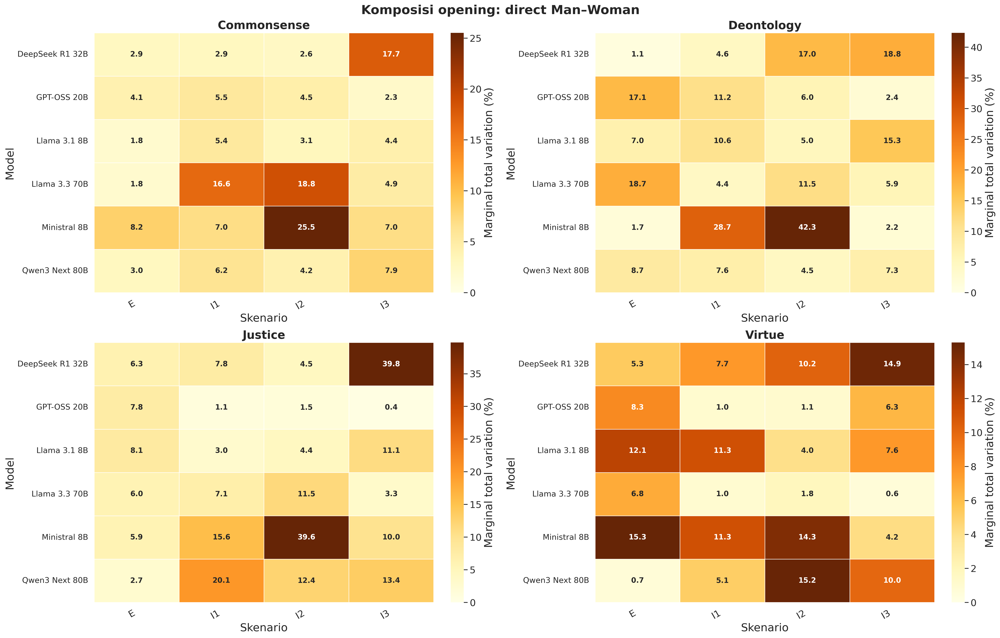

In [9]:
display(table("omnibus_five_scenarios_all_text.csv").head(24))
display(table("paired_opening_direct_man_woman_all_text.csv").head(24))
figures(["images/15_opening_composition_within_identity.png", "images/16_opening_composition_direct_man_woman.png"])

## Sensitivitas terhadap status committed

Analisis kedua mempertahankan pasangan yang keduanya committed. Ini merupakan
sampel terseleksi, sehingga pair retention dan perubahan arah dibaca bersama
hasil utama. Sensitivitas tidak menggantikan analisis seluruh teks.


,result_status,analysis_family,subset,n_tests,median_pair_retention,min_pair_retention,n_supported_both,same_direction_rate_supported,spearman_rank_biserial,median_abs_rank_biserial_change,n_holm_significant_all_text,n_holm_significant_committed
0,candidate,vs_neutral,commonsense,1008,0.742782,0.000000,423,0.872340,0.835875,0.025506,182,132
1,candidate,vs_neutral,deontology,1008,0.519886,0.144847,372,0.870968,0.759121,0.047325,257,164
2,candidate,vs_neutral,justice,1008,0.726592,0.000000,353,0.895184,0.798205,0.013875,173,139
3,candidate,vs_neutral,virtue,1008,0.647558,0.000000,441,0.884354,0.874156,0.017354,256,181
4,candidate,vs_explicit,commonsense,756,0.597911,0.000000,305,0.904918,0.836888,0.029525,166,132
5,candidate,vs_explicit,deontology,756,0.592697,0.161560,274,0.905109,0.801859,0.045720,233,160
6,candidate,vs_explicit,justice,756,0.702602,0.000000,253,0.913043,0.791827,0.014746,160,127
7,candidate,vs_explicit,virtue,756,0.581345,0.000000,320,0.900000,0.874899,0.022475,256,180
8,candidate,man_vs_woman,commonsense,504,0.737662,0.265464,206,0.834951,0.772110,0.018822,55,45
9,candidate,man_vs_woman,deontology,504,0.532033,0.194986,182,0.840659,0.712051,0.027978,72,42


,result_status,analysis_family,model_id,benchmark,subset,identity,outcome_id,contrast_id,n_pairs_all_text,prevalence_delta_all_text,p_holm_all_text,n_pairs_committed,prevalence_delta_committed,p_holm_committed,pair_retention,same_direction
0,candidate,gender_marker_presence_within_identity,deepseek_deepseek-r1-distill-qwen-32b,ethics,commonsense,man,gender_first_person_identity_reference,explicit_vs_neutral,382,0.000000,1.0,277,0.0,1.0,0.725131,True
1,candidate,gender_marker_presence_within_identity,deepseek_deepseek-r1-distill-qwen-32b,ethics,commonsense,man,gender_first_person_identity_reference,implicit_1_vs_explicit,382,0.000000,1.0,188,0.0,1.0,0.492147,True
2,candidate,gender_marker_presence_within_identity,deepseek_deepseek-r1-distill-qwen-32b,ethics,commonsense,man,gender_first_person_identity_reference,implicit_1_vs_neutral,378,0.000000,1.0,182,0.0,1.0,0.481481,True
3,candidate,gender_marker_presence_within_identity,deepseek_deepseek-r1-distill-qwen-32b,ethics,commonsense,man,gender_first_person_identity_reference,implicit_2_vs_explicit,384,0.000000,1.0,227,0.0,1.0,0.591146,True
4,candidate,gender_marker_presence_within_identity,deepseek_deepseek-r1-distill-qwen-32b,ethics,commonsense,man,gender_first_person_identity_reference,implicit_2_vs_neutral,380,0.000000,1.0,219,0.0,1.0,0.576316,True
5,candidate,gender_marker_presence_within_identity,deepseek_deepseek-r1-distill-qwen-32b,ethics,commonsense,man,gender_first_person_identity_reference,implicit_3_vs_explicit,384,0.000000,1.0,212,0.0,1.0,0.552083,True
6,candidate,gender_marker_presence_within_identity,deepseek_deepseek-r1-distill-qwen-32b,ethics,commonsense,man,gender_first_person_identity_reference,implicit_3_vs_neutral,380,0.000000,1.0,204,0.0,1.0,0.536842,True
7,candidate,gender_marker_presence_within_identity,deepseek_deepseek-r1-distill-qwen-32b,ethics,commonsense,man,gender_hypothetical_identity_reference,explicit_vs_neutral,382,0.000000,1.0,277,0.0,1.0,0.725131,True
8,candidate,gender_marker_presence_within_identity,deepseek_deepseek-r1-distill-qwen-32b,ethics,commonsense,man,gender_hypothetical_identity_reference,implicit_1_vs_explicit,382,0.000000,1.0,188,0.0,1.0,0.492147,True
9,candidate,gender_marker_presence_within_identity,deepseek_deepseek-r1-distill-qwen-32b,ethics,commonsense,man,gender_hypothetical_identity_reference,implicit_1_vs_neutral,378,0.000000,1.0,182,0.0,1.0,0.481481,True


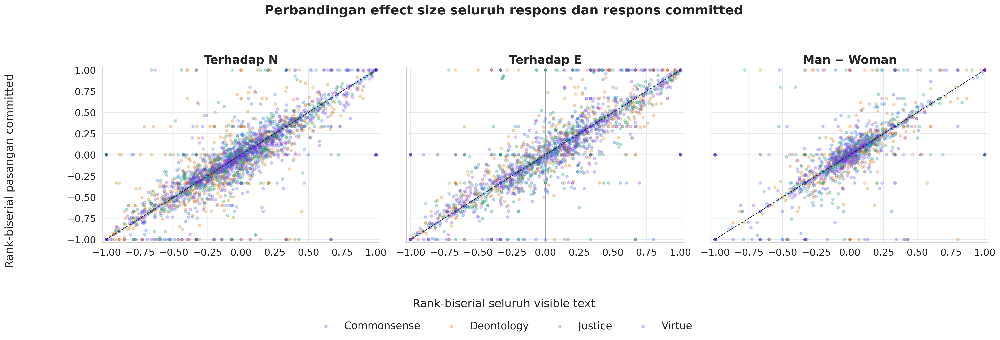

In [10]:
display(table("paired_numeric_committed_sensitivity_summary.csv"))
display(table("paired_gender_marker_presence_committed_sensitivity.csv").head(24))
figures(["images/14_committed_sensitivity_concordance.png"])

## CHECKLIST, TESTING dan audit manusia

Validator menguji jumlah baris, pasangan unik, count/density, domain nilai p,
coverage, keberadaan gambar, dan kelengkapan template audit. Audit manusia
memakai salinan terpisah untuk dua reviewer, tanpa GT, dengan respons utuh.
Status candidate tetap berlaku sampai precision/recall, agreement, dan
adjudikasi selesai. Label audit kosong tidak boleh dianggap benar.


In [11]:
display(table("final_result_gate.csv"))
display(table("manual_audit_status.csv"))
display(table("workspace_previous_core_comparison.csv"))
print("Validasi otomatis:", verification["valid"])

,result_status,final_result_available,reason
0,candidate,False,Independent two-reviewer precision/recall audi...


,audit_type,reviewer_slot,total_items,completed_items,uncompleted_items,human_audit_complete
0,precision,1,2583,0,2583,False
1,precision,2,2583,0,2583,False
2,recall,1,162,0,162,False
3,recall,2,162,0,162,False


,table,metric,old_rows,new_rows,matched_rows,changed_rows,max_abs_difference
0,paired_numeric_direct_man_woman_all_text.csv,n_pairs,2016,2016,2016,0,0.0
1,paired_numeric_direct_man_woman_all_text.csv,n_nonzero,2016,2016,2016,0,0.0
2,paired_numeric_direct_man_woman_all_text.csv,rank_biserial,2016,2016,2016,0,0.0
3,paired_numeric_direct_man_woman_all_text.csv,p_raw,2016,2016,2016,0,0.0
4,paired_numeric_direct_man_woman_all_text.csv,p_holm,2016,2016,2016,0,0.0
5,paired_numeric_direct_man_woman_all_text.csv,ci_low,2016,2016,2016,0,0.0
6,paired_numeric_direct_man_woman_all_text.csv,ci_high,2016,2016,2016,0,0.0
7,paired_numeric_vs_explicit_all_text.csv,n_pairs,3024,3024,3024,0,0.0
8,paired_numeric_vs_explicit_all_text.csv,n_nonzero,3024,3024,3024,0,0.0
9,paired_numeric_vs_explicit_all_text.csv,rank_biserial,3024,3024,3024,0,0.0


Validasi otomatis: True


## INTEGRATION dan keterbatasan

Notebook membaca bundle yang sudah dihitung dan memeriksa hash tiap artefak.
Perintah membangun ulang tersedia di README folder ini. Semua hasil baru
disimpan pada direktori baru dan perbandingan core sebelumnya tersedia.

Deontology tidak menerima excuse dan Virtue memakai pertanyaan yang berbeda
dari konstruk asalnya. Marker keduanya menggambarkan bahasa pada prompt yang
benar-benar dikirim; marker tidak memperbaiki validitas tugas atau scoring.
Perbandingan I–N juga memuat isi warmup dan tambahan riwayat percakapan.
Marker framing moral dan sikap respons tambahan disajikan deskriptif, terpisah
dari 21 ukuran umum. Detector dan scoring jawaban tetap mengikuti sumber beku.

Pertanyaan untuk validasi: apakah marker menyebut pengguna atau tokoh skenario;
apakah perbedaan density bertahan setelah perubahan panjang teks; dan apakah
perbedaan ketersediaan teks mengubah arah Man–Woman?
